# swe-bench: the SWE-RL diagram, end to end

This is the anchor notebook for `swe-bench/` (package `sarl`). It follows the diagram from the Vizuara SWE-RL lecture
(YouTube `oNHzs7wi7TY`, Abhishek Goswami; repo `abgoswam/swe_in_prod_vizuara_01` @ `8cddfb60`) one box at a time,
using real data:

- the pinned SWE-bench rows;
- the reference's mock environment;
- a real apptainer sandbox and the official `swebench` grader (on node08);
- the records of the first real GRPO run (`runs/s8-basic-lr1e-5`).

| § | box in the diagram | what runs here |
|---|---|---|
| 0 | the whole picture | setup, host checks, the diagram |
| 1 | the task | one Verified task (the lecture's) and one dev task (ours), field by field; the contamination guard |
| 2 | ENVIRONMENT | the reference's `MockEnv` state/action/observation, then a real `ApptainerEnv` *(node08)* |
| 3 | AGENT = policy + harness | both action protocols, format errors, a scripted episode with token masks, a live vLLM rollout *(node08)* |
| 4 | REWARD | apply chain + `eval.sh`; gold / empty / wrong patches graded *(node08)*; the pool gate |
| 5 | OUTER LOOP: grouped advantage | the reference formula, degenerate groups, the real groups of the basic run |
| 6 | OUTER LOOP: GRPO update | seq-mean REINFORCE on a tiny random Qwen2 (CPU), log-p before/after |
| 7 | the loop, run | the 10-step basic run: surrogate gain, weight sync, train-inference mismatch, timing |
| 8 | the reference as published | phase-1 run summary (if present) |
| 9 | lecture ↔ code | timestamp map, transcript-vs-code differences, what comes next |

**Status when built (2026-09-24).** Gates S0 and S4–S8 had passed (S4–S8 on node08). The phase-1 reference run (S1) was still in
progress; §8 reads whatever summary exists when the notebook is executed.

**Where to run it.** Execute on node08:

```bash
make -C swe-bench notebook      # nbconvert --execute on node08 → notebooks/_out/
```

On any other host, the sandbox, grader and vLLM cells skip themselves and print a `SKIPPED` line. The tokenizer and
tiny-model cells also skip on the headnode. Set `SARL_NB_SKIP_LIVE=1` to skip the live cells on node08 too, e.g. while
a training run owns the machine.

In [1]:
import ast, html, io, json, os, re, socket, sys, time, urllib.request
from collections import Counter
from pathlib import Path

for k, v in {"HF_HUB_OFFLINE": "1", "HF_DATASETS_OFFLINE": "1", "TRANSFORMERS_OFFLINE": "1",
             "TOKENIZERS_PARALLELISM": "false", "OMP_NUM_THREADS": "8"}.items():
    os.environ.setdefault(k, v)
os.environ.setdefault("HF_HOME", str(Path.home() / "hf-cache"))  # before sarl.paths reads it

try:
    import sarl
except ImportError:  # kernel without the editable install: find swe-bench/src upwards from the working directory
    _here = Path.cwd().resolve()
    sys.path.insert(0, str(next(p / "src" for p in (_here, *_here.parents) if (p / "src" / "sarl").exists())))
    import sarl

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from sarl.env import MockEnv
from sarl.env.apptainer import ApptainerEnv
from sarl.grpo import group_advantages, is_degenerate, mismatch_stats
from sarl.harness import ChatFormat, Limits, oracle_replies, run_episode
from sarl.metrics import read_jsonl
from sarl.paths import (APPTAINER, CONFIGS, DOCS, EXPERIMENTS, GRADER_VENV, HF_CACHE, MODEL_ID, MODEL_REVISION,
                        NOTEBOOKS, REPO, RUNS, SIF_DIR, UPSTREAM, UPSTREAM_SHA)
from sarl.policy import Sampling, ScriptedPolicy, VLLMPolicy
from sarl.protocol import (BACKTICKS_SYSTEM_PROMPT, BASH_TOOL, PROTOCOLS, SUBMIT, SYSTEM_PROMPT, action_text,
                           format_observation, is_submit, parse_reply, tool_call_text, tools_for)
from sarl.reward.grade import APPLY_CHAIN
from sarl.tasks import VERIFIED_REPOS, contamination_report, get_task, load_split, read_pool

# ---- host checks: live cells run only on node08 with the image present (vLLM cells also need the server)
HOST = socket.gethostname().split(".")[0]
ON_HEADNODE = HOST.startswith("bcm11-headnode")
ON_NODE08 = HOST == "node08"
SKIP_LIVE = os.environ.get("SARL_NB_SKIP_LIVE") == "1"
DEMO_TASK = "marshmallow-code__marshmallow-1359"   # smallest pool image; the tests use it too
LECTURE_TASK = "astropy__astropy-12907"            # the lecture's task (SWE-bench Verified: eval-only for us)
DEMO_SIF = SIF_DIR / f"{DEMO_TASK}.sif"
SERVE_URL = "http://localhost:8001"               # tmux swe-serve on node08 GPU0 (the only 'network' used)


def vllm_models(url=SERVE_URL, timeout=2.0):
    """Model ids the local vLLM server lists, or None when it does not answer."""
    try:
        with urllib.request.urlopen(url + "/v1/models", timeout=timeout) as r:
            return [m["id"] for m in json.load(r).get("data", [])]
    except Exception:
        return None


SANDBOX_OK = ON_NODE08 and not SKIP_LIVE and DEMO_SIF.exists() and APPTAINER.exists()
GRADER_OK = SANDBOX_OK and (GRADER_VENV / "bin" / "python").exists()
SERVED = vllm_models() if SANDBOX_OK else None
VLLM_OK = SANDBOX_OK and bool(SERVED)
QWEN_DIR = HF_CACHE / "hub" / "models--Qwen--Qwen2.5-Coder-0.5B-Instruct" / "snapshots" / MODEL_REVISION
TOKENIZER_OK = not ON_HEADNODE and (QWEN_DIR / "tokenizer_config.json").exists()  # tokenizer only, CPU
CPU_DEMO_OK = not ON_HEADNODE                                                       # tiny random model, CPU
UPSTREAM_OK = (UPSTREAM / "utils.py").exists()
# the final basic run (after the review fixes); earlier runs stay in experiments/runs/ for comparison
S8 = next((RUNS / n for n in ("s8-basic-v3b", "s8-basic-v2", "s8-basic-lr1e-5") if (RUNS / n / "metrics.jsonl").exists()),
          EXPERIMENTS / "runs" / "s8-basic-v3b")

FIG_DIR = NOTEBOOKS / "_out" / "figures"
SANDBOX_PATCH, LIVE, GRADES = "", {}, {}             # filled by guarded cells, read by later ones

# ---- look: reference palette (blue / orange / aqua slots), recessive axes, ink-coloured text
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gray": "#9a9994", "light": "#d9d8d3"}
C_POLICY, C_ORACLE = C["aqua"], C["orange"]        # aqua = the diagram's teal policy tokens
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 9.5, "axes.titlelocation": "left", "axes.labelsize": 9,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 1.8, "lines.markersize": 5, "legend.frameon": False, "legend.fontsize": 8,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE})
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 80)

# ---- token kinds for the mask views: 0 prompt, 1 policy (mask 1), 2 env/harness (mask 0), 3 closer added by harness
KIND_NAMES = ["prompt (system + issue)", "policy tokens (mask 1)", "environment / harness turns (mask 0)",
              "<|im_end|> added by the harness"]
KIND_COLORS = [C["light"], C_POLICY, C["gray"], C_ORACLE]
KIND_TINTS = ["#efeeea", "#c8eedf", "#dcdbd6", "#fbd6c6"]
IM_END = 151645


def show(fig, name):
    """Render as PNG (works under Agg or inline), keep a copy in notebooks/_out/figures, close the figure."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=110, bbox_inches="tight"); plt.close(fig)
    (FIG_DIR / f"{name}.png").write_bytes(buf.getvalue())
    display(Image(data=buf.getvalue()))


def skipped(what, why):
    print(f"SKIPPED — {what}: {why}")


def clip(s, n=1200):
    s = str(s)
    return s if len(s) <= n else s[: n - 200] + f"\n[... {len(s) - n} chars elided ...]\n" + s[-200:]


def load_json(p):
    p = Path(p)
    if p.suffix == ".gz":
        import gzip

        with gzip.open(p, "rt") as f:
            return json.load(f)
    return json.loads(p.read_text())


S8_TRAJ = Path(load_json(S8 / "summary.json").get("trajectories", S8 / "trajectories")) if (S8 / "summary.json").exists() else S8 / "trajectories"
if not S8_TRAJ.exists():
    S8_TRAJ = S8 / "trajectories"  # older runs kept per-token dumps under runs/


def upstream_constants(path=UPSTREAM / "utils.py", names=("TARGET", "MOCK_FILE")):
    """Literal constants from the fetched reference, read WITHOUT executing it (it imports torch/IPython)."""
    out = {}
    for node in ast.parse(Path(path).read_text()).body:
        if isinstance(node, ast.Assign) and len(node.targets) == 1 and getattr(node.targets[0], "id", None) in names:
            out[node.targets[0].id] = ast.literal_eval(node.value)
    return out


def token_kinds(ids, mask, im_end=IM_END):
    mask = np.asarray(mask)
    first = int(np.argmax(mask)) if mask.any() else len(mask)
    k = np.where(mask == 1, 1, 2)
    k[:first] = 0
    closers = (mask[1:] == 0) & (mask[:-1] == 1) & (np.asarray(ids[1:]) == im_end)
    k[1:][closers] = 3
    return k


def mask_strip(ax, ids, mask, label):
    k = token_kinds(ids, mask)
    ax.imshow(k[None, :], aspect="auto", interpolation="nearest", cmap=ListedColormap(KIND_COLORS), vmin=-0.5, vmax=3.5,
              extent=(0, len(k), 0, 1))
    ax.set_yticks([]); ax.grid(False); ax.set_xlim(0, len(k))
    ax.set_title(f"{label}: {len(k):,} tokens, {int(np.sum(np.asarray(mask) == 1)):,} policy tokens", fontsize=8.5)


def token_html(tok, ids, mask, max_seg=500):
    """Contiguous runs of one token kind as coloured spans (hover shows kind and token count)."""
    k, parts, i = token_kinds(ids, mask), [], 0
    while i < len(ids):
        j = i
        while j < len(ids) and k[j] == k[i]:
            j += 1
        text = tok.decode(ids[i:j])
        if len(text) > max_seg:
            text = text[: max_seg // 2] + f" … [{j - i} tokens] … " + text[-max_seg // 2:]
        parts.append(f'<span title="{html.escape(KIND_NAMES[k[i]])}: {j - i} tokens" style="background:{KIND_TINTS[k[i]]};'
                     f'color:{INK};border-radius:2px">{html.escape(text)}</span>')
        i = j
    legend = " ".join(f'<span style="background:{t};color:{INK};padding:0 4px;border-radius:2px">{html.escape(n)}</span>'
                      for n, t in zip(KIND_NAMES, KIND_TINTS))
    return (f'<div style="font-size:11px;margin:4px 0">{legend}</div><div style="font-family:monospace;font-size:11px;'
            f'white-space:pre-wrap;line-height:1.4;max-height:420px;overflow:auto;border:1px solid {GRID};padding:6px">'
            + "".join(parts) + "</div>")


def mask_runs(mask):
    """(start, end) of every run of mask 1 = one policy reply each."""
    runs, i, m = [], 0, list(mask)
    while i < len(m):
        if m[i]:
            j = i
            while j < len(m) and m[j]:
                j += 1
            runs.append((i, j)); i = j
        else:
            i += 1
    return runs


def rerender_ids(tok, messages, protocol):
    full = tok.apply_chat_template(messages, tools=tools_for(protocol) or None, add_generation_prompt=False, tokenize=False)
    return tok(full, add_special_tokens=False)["input_ids"]


if ON_HEADNODE:
    print("NOTE: running on the headnode. Only the file-reading cells will run; execute with `make -C swe-bench notebook`.")
print(f"sarl {sarl.__version__} from {REPO}\nhost={HOST}")
pd.DataFrame([
    ("sandbox cells (apptainer)", SANDBOX_OK, f"node08 and {DEMO_SIF} exists" + (" [SARL_NB_SKIP_LIVE=1]" if SKIP_LIVE else "")),
    ("grader cells (swebench 5.0.2)", GRADER_OK, f"sandbox and {GRADER_VENV}/bin/python"),
    ("vLLM cells", VLLM_OK, f"sandbox and {SERVE_URL}/v1/models answers: {SERVED}"),
    ("tokenizer cells (CPU)", TOKENIZER_OK, f"not the headnode and Qwen @ {MODEL_REVISION[:8]} in {HF_CACHE}"),
    ("tiny-model CPU demo", CPU_DEMO_OK, "not the headnode"),
    ("reference/_upstream fetched", UPSTREAM_OK, f"{UPSTREAM} @ {UPSTREAM_SHA[:8]}"),
    ("basic run records", (S8 / "metrics.jsonl").exists(), str(S8.relative_to(REPO))),
], columns=["cells", "enabled", "condition"])

sarl 0.1.0 from /home/yashp/Agentic-RL/swe-bench
host=node08


,cells,enabled,condition
0,sandbox cells (apptainer),True,node08 and /tmp/swe-sif/marshmallow-code__marshmallow-1359.sif exists
1,grader cells (swebench 5.0.2),True,sandbox and /var/tmp/swe/grader-venv/bin/python
2,vLLM cells,True,"sandbox and http://localhost:8001/v1/models answers: ['policy', 'policy-b36df2-s10']"
3,tokenizer cells (CPU),True,not the headnode and Qwen @ ea3f2471 in /home/yashp/hf-cache
4,tiny-model CPU demo,True,not the headnode
5,reference/_upstream fetched,True,/home/yashp/Agentic-RL/swe-bench/reference/_upstream @ 8cddfb60
6,basic run records,True,runs/s8-basic-v3b


### The whole picture

The diagram, box by box, and the `sarl` code that implements each box:

| diagram box | what it does | `sarl` |
|---|---|---|
| **POLICY πθ** (vLLM, GPU) | text in → one action out; stateless | `policy.VLLMPolicy` returns token ids + log-probs; `policy.ScriptedPolicy` is the oracle |
| **HARNESS** (CPU) | owns the transcript and the loop: prepare → call → parse → execute → append | `harness.run_episode`, `harness.ChatFormat` |
| **ACTION** | ONE bash call: `<tool_call>{"name":"bash","command":…}</tool_call>` | `protocol.parse_reply` (`tool_call`, or the reference's `backticks`) |
| **OBSERVATION** | `<tool_response><returncode>…</returncode><output>…</output>`, mask 0 | `protocol.format_observation`, appended as a `tool` turn |
| **ENVIRONMENT** | Docker container at `/testbed` | `env.ApptainerEnv` (the cluster has no Docker); `env.MockEnv` for the reference's demo |
| **INNER LOOP** exits | submit · 50 turns · 32k context · 30 min | `harness.Limits` → `Trajectory.exit_reason` |
| **REWARD** | episode end only: wipe tree, apply patch, run tests → r ∈ [0, 1] | `reward.grade`: a fresh container, the apply chain, `eval.sh`, then the swebench log parser |
| **OUTER LOOP** | trajectory (tokens · masks · log-probs) + reward → grouped advantage (16/task) → GRPO update → πθ′ back into vLLM | `grpo.group_advantages`, `grpo.LoRATrainer`, `train.LoraSync` |

The image below comes from `reference/_upstream/`. It is fetched, not vendored, because the upstream repo has no licence.

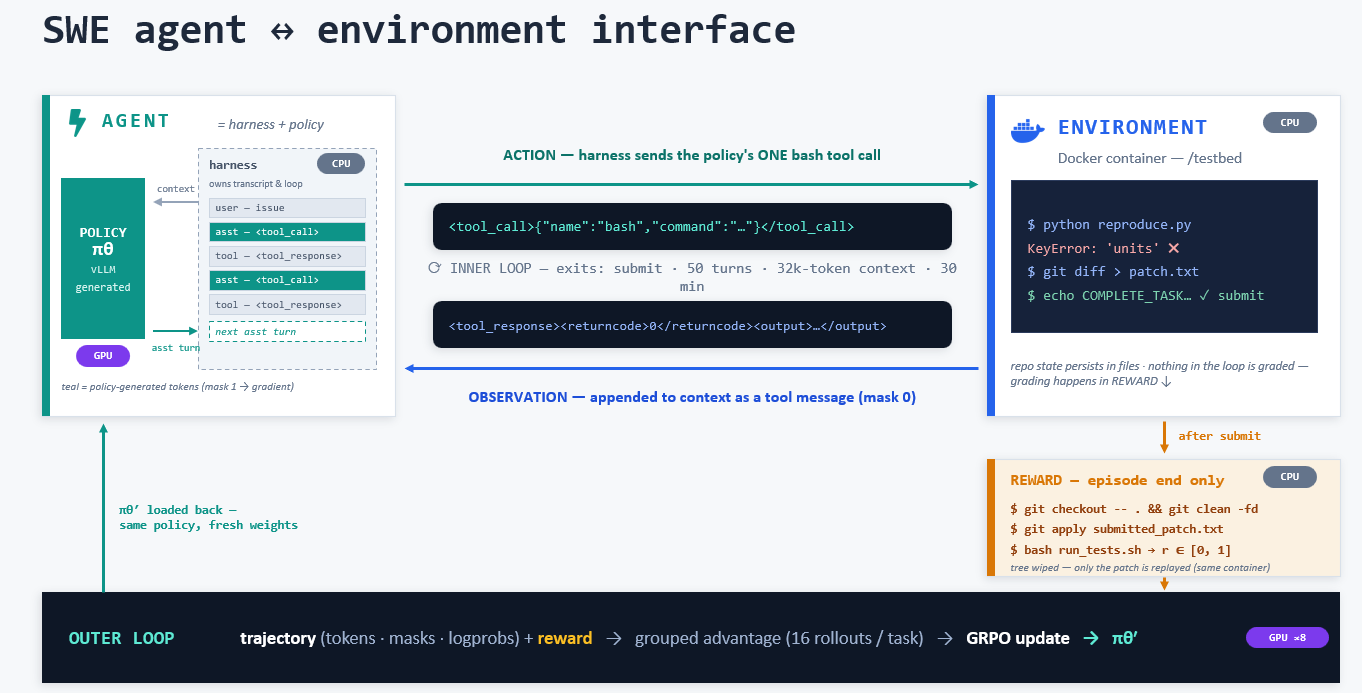

In [2]:
png = UPSTREAM / "swe_agent_env_interface.png"
if png.exists():
    display(Image(filename=str(png), width=920))
else:
    skipped("diagram", "reference/_upstream not fetched (bash reference/fetch.sh); the table above is the same diagram")

## §1 · One task, field by field

A SWE-bench task is a GitHub issue plus the PR that fixed it. SWE-bench splits the PR into two parts:

- the source half becomes `patch`, the gold fix;
- the test half becomes `test_patch`.

It then pins the repository at `base_commit`, just before the PR. Two tasks are shown here:

- `astropy__astropy-12907`, the lecture's task. It is a SWE-bench **Verified** instance (split `verified_princeton`,
  the reference's copy). The lecture trains on it "for illustrative purposes" (0:15). For us, Verified is
  **evaluation-only**.
- `marshmallow-code__marshmallow-1359`, a training task from our pool. It comes from the SWE-bench **dev** split,
  whose repos, ids and commits are disjoint from Verified.

In [3]:
lecture = get_task(LECTURE_TASK, splits=("verified_princeton",))
train_t = get_task(DEMO_TASK, splits=("dev",))
pd.DataFrame({t.instance_id: {
    "split": t.split, "repo": t.repo, "base_commit": t.base_commit[:10], "version": t.version,
    "FAIL_TO_PASS": len(t.fail_to_pass), "PASS_TO_PASS": len(t.pass_to_pass),
    "gold patch": f"{len(t.patch)} chars, {t.n_patch_files} file", "test_patch": f"{len(t.test_patch)} chars",
    "issue": f"{len(t.problem_statement)} chars", "contaminates_eval": t.contaminates_eval, "image": t.image,
} for t in (lecture, train_t)})

,astropy__astropy-12907,marshmallow-code__marshmallow-1359
split,verified_princeton,dev
repo,astropy/astropy,marshmallow-code/marshmallow
base_commit,d16bfe05a7,b40a0f4e33
version,4.3,3.0
FAIL_TO_PASS,2,1
PASS_TO_PASS,13,76
gold patch,"470 chars, 1 file","483 chars, 1 file"
test_patch,1415 chars,932 chars
issue,1246 chars,1748 chars
contaminates_eval,True,False


In [4]:
# Who sees what. The agent gets the issue and nothing else; the tests that define "fixed" never enter its sandbox.
pd.DataFrame([
    ("problem_statement", "the agent", "its entire input: a raw GitHub issue (no file names, no tests)"),
    ("patch (gold)", "nobody in a policy rollout", "sarl uses it for the scripted oracle and the pool gate only"),
    ("test_patch", "the grader", "adds the tests that define 'fixed'; applied inside eval.sh, never in the sandbox"),
    ("FAIL_TO_PASS", "the grader", "must go red → green: 'you solved the issue'"),
    ("PASS_TO_PASS", "the grader", "must stay green: 'you broke nothing'"),
    ("image / eval_script", "environment / grader", "the container at base_commit; the script that runs the tests"),
], columns=["field", "who sees it", "job"])

,field,who sees it,job
0,problem_statement,the agent,"its entire input: a raw GitHub issue (no file names, no tests)"
1,patch (gold),nobody in a policy rollout,sarl uses it for the scripted oracle and the pool gate only
2,test_patch,the grader,"adds the tests that define 'fixed'; applied inside eval.sh, never in the sandbox"
3,FAIL_TO_PASS,the grader,must go red → green: 'you solved the issue'
4,PASS_TO_PASS,the grader,must stay green: 'you broke nothing'
5,image / eval_script,environment / grader,the container at base_commit; the script that runs the tests


In [5]:
for t in (lecture, train_t):
    print(f"==== {t.instance_id} [{t.split}]: problem_statement (the agent's whole input) ====")
    print(clip(t.problem_statement, 1400), "\n")

==== astropy__astropy-12907 [verified_princeton]: problem_statement (the agent's whole input) ====
Modeling's `separability_matrix` does not compute separability correctly for nested CompoundModels
Consider the following model:

```python
from astropy.modeling import models as m
from astropy.modeling.separable import separability_matrix

cm = m.Linear1D(10) & m.Linear1D(5)
```

It's separability matrix as you might expect is a diagonal:

```python
>>> separability_matrix(cm)
array([[ True, False],
       [False,  True]])
```

If I make the model more complex:
```python
>>> separability_matrix(m.Pix2Sky_TAN() & m.Linear1D(10) & m.Linear1D(5))
array([[ True,  True, False, False],
       [ True,  True, False, False],
       [False, False,  True, False],
       [False, False, False,  True]])
```

The output matrix is again, as expected, the outputs and inputs to the linear models are separable and independent of each other.

If however, I nest these compound models:
```python
>>> separabil

In [6]:
# The grader's half of the training task (hidden from the agent).
print("FAIL_TO_PASS:", *train_t.fail_to_pass, sep="\n  ")
print(f"PASS_TO_PASS: {len(train_t.pass_to_pass)} tests, e.g.", *train_t.pass_to_pass[:4], sep="\n  ")
print("\ntest_patch:\n" + clip(train_t.test_patch, 1500))
print(f"\nlecture task: FAIL_TO_PASS {len(lecture.fail_to_pass)}, PASS_TO_PASS {len(lecture.pass_to_pass)} (the lecture says 2 and 13, 0:18-0:25)")

FAIL_TO_PASS:
  tests/test_fields.py::TestParentAndName::test_datetime_list_inner_format
PASS_TO_PASS: 76 tests, e.g.
  tests/test_fields.py::test_field_aliases[Integer-Integer]
  tests/test_fields.py::test_field_aliases[String-String]
  tests/test_fields.py::test_field_aliases[Boolean-Boolean]
  tests/test_fields.py::test_field_aliases[Url-Url]

test_patch:
diff --git a/tests/test_fields.py b/tests/test_fields.py
--- a/tests/test_fields.py
+++ b/tests/test_fields.py
@@ -169,6 +169,20 @@ class OtherSchema(MySchema):
         assert schema2.fields["foo"].key_field.root == schema2
         assert schema2.fields["foo"].value_field.root == schema2
 
+    # Regression test for https://github.com/marshmallow-code/marshmallow/issues/1357
+    def test_datetime_list_inner_format(self, schema):
+        class MySchema(Schema):
+            foo = fields.List(fields.DateTime())
+            bar = fields.Tuple((fields.DateTime(),))
+
+            class Meta:
+                datetimeformat = "iso8

**The contamination guard.** `contamination_report(train, eval)` flags a training task in three cases: its repo is
one of the 12 Verified repos, its instance id appears in Verified, or its base commit does. The guard must come back
clean for every pool. The last row feeds the lecture's own task through the guard, which is exactly the task the
guard exists to catch.

In [7]:
dev, ver = load_split("dev"), load_split("verified")
pool = read_pool(CONFIGS / "pool_dev.txt")
reports = {"training pool (configs/pool_dev.txt) vs Verified": contamination_report(pool, ver),
           "whole dev split vs Verified": contamination_report(dev, ver),
           "the lecture's task vs Verified": contamination_report([lecture], ver)}
display(pd.DataFrame([{"check": k, "n_train": r["n_train"], "n_eval": r["n_eval"], **{f"{h} hits": len(v) for h, v in r["hits"].items()},
                       "clean": r["clean"]} for k, r in reports.items()]))
print("dev repos:     ", dict(Counter(t.repo for t in dev).most_common()))
print("Verified repos:", dict(Counter(t.repo for t in ver).most_common()))
print("pool:          ", [t.instance_id for t in pool])

,check,n_train,n_eval,repo hits,instance_id hits,base_commit hits,clean
0,training pool (configs/pool_dev.txt) vs Verified,8,500,0,0,0,True
1,whole dev split vs Verified,225,500,0,0,0,True
2,the lecture's task vs Verified,1,500,1,1,1,False


dev repos:      {'pvlib/pvlib-python': 63, 'pydicom/pydicom': 56, 'sqlfluff/sqlfluff': 50, 'pylint-dev/astroid': 31, 'pyvista/pyvista': 16, 'marshmallow-code/marshmallow': 9}
Verified repos: {'django/django': 231, 'sympy/sympy': 75, 'sphinx-doc/sphinx': 44, 'matplotlib/matplotlib': 34, 'scikit-learn/scikit-learn': 32, 'astropy/astropy': 22, 'pydata/xarray': 22, 'pytest-dev/pytest': 19, 'pylint-dev/pylint': 10, 'psf/requests': 8, 'mwaskom/seaborn': 2, 'pallets/flask': 1}
pool:           ['pylint-dev__astroid-946', 'marshmallow-code__marshmallow-1359', 'pydicom__pydicom-811', 'pylint-dev__astroid-1614', 'sqlfluff__sqlfluff-1625', 'pydicom__pydicom-1256', 'pydicom__pydicom-1694', 'pylint-dev__astroid-1268']


## §2 · The environment

$$\text{state} \;\xrightarrow{\ \text{action}\ }\; \text{state}' \;+\; \text{observation}$$

- **state**: the files in the repository;
- **action**: one bash command;
- **observation**: what the command printed, plus its return code. This is all the agent ever sees.

The candidate patch is the difference between the initial state and the final state (lecture 0:58–1:05).

### 2.1 The reference's mock (mirrors its §2)

`sarl.env.MockEnv` has the same semantics as the reference's `utils.MockEnv`. Its state is a dict holding one file:
the real `_cstack` from astropy's `separable.py` at `base_commit`, loaded from `reference/_upstream/utils.py`. The file
is parsed, not executed. The bug is an asymmetry: the `cleft` branch assigns `left`, but the `cright` branch assigns
`1`.

In [8]:
if not UPSTREAM_OK:
    skipped("mock environment", "reference/_upstream not fetched (bash reference/fetch.sh)")
else:
    UP = upstream_constants()
    TARGET, MOCK_FILE = UP["TARGET"], UP["MOCK_FILE"]
    FIXED = MOCK_FILE.replace("= 1", "= right")                    # the one-token fix
    menv = MockEnv({TARGET: MOCK_FILE}, lecture.fail_to_pass)
    print("state = files in the environment:", list(menv.fs), "\n")
    print(menv.fs[TARGET])

state = files in the environment: ['astropy/modeling/separable.py'] 

def _cstack(left, right):
    """
    Function corresponding to '&' operation.

    Parameters
    ----------
    left, right : `astropy.modeling.Model` or ndarray
        If input is of an array, it is the output of `coord_matrix`.

    Returns
    -------
    result : ndarray
        Result from this operation.

    """
    noutp = _compute_n_outputs(left, right)

    if isinstance(left, Model):
        cleft = _coord_matrix(left, 'left', noutp)
    else:
        cleft = np.zeros((noutp, left.shape[1]))
        cleft[: left.shape[0], : left.shape[1]] = left
    if isinstance(right, Model):
        cright = _coord_matrix(right, 'right', noutp)
    else:
        cright = np.zeros((noutp, right.shape[1]))
        cright[-right.shape[0]:, -right.shape[1]:] = 1

    return np.hstack([cleft, cright])


In [9]:
# Take actions. Read-only commands return an observation and leave the state alone; only the write moves it.
if UPSTREAM_OK:
    rows, grep_res = [], None
    for action in ["ls", f'grep -n "cright" {TARGET}', "python -m pytest", "pip install -e .",
                   f"cat > {TARGET} <<'EOF'\n{FIXED}\nEOF"]:
        before = dict(menv.fs)
        res = menv.run(action)
        if action.startswith("grep"):
            grep_res = res
        rows.append({"action": action.splitlines()[0] + (" ..." if "\n" in action else ""), "state changed": menv.fs != before,
                     "returncode": res.returncode, "observation": res.output.replace("\n", " | ")[:70]})
    display(pd.DataFrame(rows))
    print("what the harness appends after the grep (the diagram's OBSERVATION):\n")
    print(format_observation(grep_res.returncode, grep_res.output))

,action,state changed,returncode,observation
0,ls,False,0,astropy/modeling/separable.py | setup.py | README.rst | tests/
1,"grep -n ""cright"" astropy/modeling/separable.py",False,0,"24: cright = _coord_matrix(right, 'right', noutp) | 26:"
2,python -m pytest,False,1,FAILED astropy/modeling/tests/test_separable.py::test_separable[compou
3,pip install -e .,False,127,"bash: pip: command not found | [mock env] implements only: ls, cat, gr"
4,cat > astropy/modeling/separable.py <<'EOF' ...,True,0,[mock env] wrote 29 lines to astropy/modeling/separable.py


what the harness appends after the grep (the diagram's OBSERVATION):

<returncode>0</returncode>
<output>
24:        cright = _coord_matrix(right, 'right', noutp)
26:        cright = np.zeros((noutp, right.shape[1]))
27:        cright[-right.shape[0]:, -right.shape[1]:] = 1
29:    return np.hstack([cleft, cright])
</output>


In [10]:
# The new state, and its difference from the initial state: that difference IS the candidate patch.
if UPSTREAM_OK:
    print(menv.patch())

--- a/astropy/modeling/separable.py
+++ b/astropy/modeling/separable.py
@@ -24,6 +24,6 @@
         cright = _coord_matrix(right, 'right', noutp)
     else:
         cright = np.zeros((noutp, right.shape[1]))
-        cright[-right.shape[0]:, -right.shape[1]:] = 1
+        cright[-right.shape[0]:, -right.shape[1]:] = right
 
     return np.hstack([cleft, cright])


### 2.2 The real environment: one unprivileged apptainer instance per rollout *(node08)*

The cluster has no Docker, so `ApptainerEnv` runs the SWE-bench image as an apptainer instance:
`instance start --fakeroot --containall --writable-tmpfs`. What gate S4 established:

- Inside the instance you are uid 0 in `/testbed`, with the `testbed` conda env active.
- State persists across execs, and each exec takes about 0.7 s.
- `timeout -k` kills runaway commands.
- The image's HEAD is a commit named "SWE-bench", so the patch is `git diff HEAD`, new files included.

One trap: `--containall` implies `--cleanenv`, which leaves `LANG=C` inside the container. The env therefore passes
`APPTAINERENV_LANG=C.UTF-8`, checked in the third command below (§4 explains why).

This cell runs a few read-only commands and then makes one edit. The edit is the gold fix, applied as a Python string
replacement, so the patch comes from the sandbox and not from the dataset.

In [11]:
if not SANDBOX_OK:
    skipped("apptainer sandbox", f"needs node08 and {DEMO_SIF} (host={HOST})")
else:
    target = re.search(r"^diff --git a/(\S+)", train_t.patch, re.M).group(1)
    changed = [l for l in train_t.patch.splitlines() if l[:1] in "+-" and not l.startswith(("+++", "---"))]
    old, new = changed[0][1:].strip(), changed[1][1:].strip()
    edit = ("python - <<'PY'\nimport io\n"
            f"p = {target!r}\ns = io.open(p, encoding='utf-8').read()\nprint('occurrences:', s.count({old!r}))\n"
            f"io.open(p, 'w', encoding='utf-8').write(s.replace({old!r}, {new!r}, 1))\nPY")
    cmds = ["id -u; pwd; which python", "git log --oneline -2",
            "echo LANG=$LANG; python -c 'import sys; print(sys.getfilesystemencoding())'",
            f"grep -n 'SCHEMA_OPTS_VAR_NAME' {target}", edit, "git status --short"]
    rows = []
    with ApptainerEnv(DEMO_SIF, command_timeout=60) as env:
        for c in cmds:
            r = env.run(c)
            rows.append({"action": c.splitlines()[0] + (" ..." if "\n" in c else ""), "rc": r.returncode,
                         "seconds": round(r.seconds, 2), "observation": r.output.strip().replace("\n", " | ")[:90]})
        SANDBOX_PATCH = env.patch()
    display(pd.DataFrame(rows))
    print("env.patch() = git diff HEAD inside the instance:\n" + SANDBOX_PATCH)
    print("same -/+ lines as the gold patch:", changed[0] in SANDBOX_PATCH and changed[1] in SANDBOX_PATCH)

,action,rc,seconds,observation
0,id -u; pwd; which python,0,0.40,0 | /testbed | /opt/miniconda3/envs/testbed/bin/python
1,git log --oneline -2,0,0.22,8ad28316 SWE-bench | b40a0f4e Merge branch '2.x-line' into dev
2,echo LANG=$LANG; python -c 'import sys; print(sys.getfilesystemencoding())',0,0.31,LANG=C.UTF-8 | utf-8
3,grep -n 'SCHEMA_OPTS_VAR_NAME' src/marshmallow/fields.py,0,0.22,"1098: SCHEMA_OPTS_VAR_NAME = ""datetimeformat"" | 1117: or getattr(schema...."
4,python - <<'PY' ...,0,0.22,occurrences: 1
5,git status --short,0,0.24,M src/marshmallow/fields.py


env.patch() = git diff HEAD inside the instance:
diff --git a/src/marshmallow/fields.py b/src/marshmallow/fields.py
index 0b18e7dd..55e36e26 100644
--- a/src/marshmallow/fields.py
+++ b/src/marshmallow/fields.py
@@ -1114,7 +1114,7 @@ class DateTime(Field):
         super()._bind_to_schema(field_name, schema)
         self.format = (
             self.format
-            or getattr(schema.opts, self.SCHEMA_OPTS_VAR_NAME)
+            or getattr(self.root.opts, self.SCHEMA_OPTS_VAR_NAME)
             or self.DEFAULT_FORMAT
         )
 

same -/+ lines as the gold patch: True


## §3 · The agent = model + harness

$$\textbf{agent} = \textbf{policy } \pi_\theta \;+\; \textbf{harness}$$

- **The model** is text in, text out, and stateless (lecture 1:14). It is the only part that learns.
- **The harness** is deterministic code that is never trained. It renders the prompt, calls the model, parses one
  action out of the reply, executes it, and appends the observation. It owns the transcript.

### 3.1 The action protocol: two of them

The diagram's action is one JSON tool call. Qwen2.5 renders tool calls in the hermes style,
`<tool_call>{"name": "bash", "arguments": {"command": …}}</tool_call>`, and the parser also accepts the diagram's
shorthand `{"name":"bash","command":…}`. The reference instead uses exactly one fenced ```` ```bash ```` block per
reply.

Gate S6 found that Qwen2.5-Coder-0.5B produced **0 valid JSON tool calls in 48 turns** (16 real episodes), even with
an example in the prompt. With the fenced protocol, 92% of its turns were valid. So the basic run uses `backticks`.
That fits the lecture's advice at 2:50: a base model that does not know the action space needs SFT, or a larger
model, before RL on it.

In [12]:
print("==== tool_call protocol: system prompt (+ the bash tool in the chat template's tools block) ====")
print(SYSTEM_PROMPT, "\n\ntool schema:", json.dumps(BASH_TOOL["function"]["parameters"]))
print("\n==== backticks protocol (the reference's) ====")
print(BACKTICKS_SYSTEM_PROMPT)

==== tool_call protocol: system prompt (+ the bash tool in the chat template's tools block) ====
You are a software engineer fixing a bug in a Python repository. The repository is checked out in /testbed.

Work in small steps. Every reply must contain a short thought followed by exactly ONE bash tool call.

Recommended workflow:
1. Find the relevant code (ls, grep -rn, sed -n 'START,ENDp' FILE).
2. Reproduce the bug with a small script if useful.
3. Edit the source code (for example with sed -i, or a python one-liner). Do not modify tests.
4. Verify your fix.
5. When you are done, submit by running exactly: echo COMPLETE_TASK_AND_SUBMIT_FINAL_OUTPUT

Your changes to the repository are collected automatically when you submit.

Example of a correct reply (one thought, then one tool call, nothing else):
Let me look at the repository layout first.
<tool_call>
{"name": "bash", "arguments": {"command": "ls"}}
</tool_call> 

tool schema: {"type": "object", "properties": {"command": {"type": "

In [13]:
# The parse step. Anything but exactly one well-formed action is a format error: fed back to the policy (mask 0),
# counted, never executed, and never allowed to crash the batch (the lecturer's trial_10 parser bug).
examples = [
    ("tool_call", tool_call_text("grep -rn SCHEMA_OPTS_VAR_NAME src/", "Find where the format option is read.")),
    ("tool_call", '<tool_call>{"name":"bash","command":"pwd"}</tool_call>'),
    ("tool_call", "I will run ls to look around."),
    ("tool_call", tool_call_text("ls") + tool_call_text("pwd")),
    ("tool_call", "<tool_call>{bad json}</tool_call>"),
    ("tool_call", '<tool_call>"ls"</tool_call>'),
    ("tool_call", '<tool_call>{"name":"bash","arguments":{"command":"ls"}'),
    ("tool_call", '<tool_call>{"name":"python","arguments":{"command":"1+1"}}</tool_call>'),
    ("backticks", action_text("sed -n '1110,1125p' src/marshmallow/fields.py", "Look at _bind_to_schema.", "backticks")),
    ("backticks", "Run the tests.\n```\npytest -x tests/test_fields.py\n```"),
    ("backticks", "I would run `ls` here."),
    ("backticks", f"Done.\n```bash\necho {SUBMIT}\n```"),
]
rows = []
for proto, reply in examples:
    p = parse_reply(reply, proto)
    rows.append({"protocol": proto, "reply": reply.replace("\n", "⏎")[:64], "ok": p.ok, "command": p.command,
                 "submit": bool(p.command) and is_submit(p.command), "format error fed back": (p.error or "")[:70]})
pd.DataFrame(rows)

,protocol,reply,ok,command,submit,format error fed back
0,tool_call,"Find where the format option is read.⏎<tool_call>⏎{""name"": ""bash",True,grep -rn SCHEMA_OPTS_VAR_NAME src/,False,
1,tool_call,"<tool_call>{""name"":""bash"",""command"":""pwd""}</tool_call>",True,pwd,False,
2,tool_call,I will run ls to look around.,False,NaN,False,Format error: your reply contained no tool call. Reply with a short th
3,tool_call,"<tool_call>⏎{""name"": ""bash"", ""arguments"": {""command"": ""ls""}}⏎</t",False,NaN,False,Format error: your reply contained 2 tool calls. Use exactly ONE bash
4,tool_call,<tool_call>{bad json}</tool_call>,False,NaN,False,Format error: the tool call is not valid JSON (Expecting property name
5,tool_call,"<tool_call>""ls""</tool_call>",False,NaN,False,"Format error: the tool call decoded to a str, not an object. The call"
6,tool_call,"<tool_call>{""name"":""bash"",""arguments"":{""command"":""ls""}",False,NaN,False,Format error: an unclosed <tool_call> (the reply was cut off?). The ca
7,tool_call,"<tool_call>{""name"":""python"",""arguments"":{""command"":""1+1""}}</tool",False,NaN,False,Format error: unknown tool 'python' (only 'bash' exists). The call mus
8,backticks,"Look at _bind_to_schema.⏎```bash⏎sed -n '1110,1125p' src/marshma",True,"sed -n '1110,1125p' src/marshmallow/fields.py",False,
9,backticks,Run the tests.⏎```⏎pytest -x tests/test_fields.py⏎```,True,pytest -x tests/test_fields.py,False,


In [14]:
# The observation format (mini-swe-agent's): return code + output; over 10k chars it keeps head and tail with a warning.
print(format_observation(0, "src/marshmallow/fields.py:1117:            or getattr(schema.opts, self.SCHEMA_OPTS_VAR_NAME)\n"))
print()
print(clip(format_observation(1, "E" * 25_000), 700))
print()
print(format_observation(None, "", timed_out=True))

<returncode>0</returncode>
<output>
src/marshmallow/fields.py:1117:            or getattr(schema.opts, self.SCHEMA_OPTS_VAR_NAME)
</output>

<returncode>1</returncode>
<warning>The output was 25000 characters; 15000 characters in the middle were elided. Use more selective commands (grep, head, sed -n).</warning>
<output_head>
EEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEE
[... 9532 chars elided ...]
EEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEE
</output_tail>

<returncode>timeout</returncode>
<output>
</output>


### 3.2 The harness loop

`sarl.harness.run_episode` keeps the transcript as **token ids**, not text. The prompt is rendered once. Each policy
reply is appended exactly as sampled, with mask 1 and its log-probs. Each observation is appended as a templated turn
with mask 0. The loop:

```text
ids  = render(system, issue)                           # mask 0
for turn in range(max_turns):                          # exits: submitted · max_turns · context · wall_clock · format_errors
    reply_ids, logprobs = policy.generate(ids)         # mask 1; an unclosed reply gets a harness <|im_end|> with mask 0
    action = parse_reply(text, protocol)               # exactly one action, else a format error (fed back, mask 0)
    obs    = env.run(action)                           # returncode + output
    ids   += tool_turn(format_observation(obs))        # mask 0 (a user turn in the backticks protocol)
patch = env.patch()                                    # graded once, after the episode (§4)
```

The exits, compared with the diagram and the reference:

In [15]:
cfg8 = load_json(S8 / "config.json") if (S8 / "config.json").exists() else {"limits": {}}
lim = Limits()
pd.DataFrame([
    ("turns", "50", "4, and the only exit", lim.max_turns, cfg8["limits"].get("max_turns")),
    ("context", "32k tokens", "prompt cut at 3072 tokens", lim.max_context_tokens, cfg8["limits"].get("max_context_tokens")),
    ("wall clock", "30 min", "none", f"{lim.wall_clock_s:.0f} s", cfg8["limits"].get("wall_clock_s")),
    ("submit", "echo COMPLETE_TASK… (+ patch)", "none", f"echo {SUBMIT}", "same"),
    ("reply length", "n/a", "max_new_tokens 200", lim.max_new_tokens, cfg8["limits"].get("max_new_tokens")),
    ("observation", "tool message", "user message, first 800 chars", f"tool message, {lim.max_obs_chars:,}-char head/tail", "user message (backticks)"),
    ("format errors", "error fed back", "'No command found', counts as a turn", f"fed back; {lim.max_format_errors} in a row end it", cfg8["limits"].get("max_format_errors")),
], columns=["limit", "diagram", "reference notebook", "sarl Limits()", "basic run (S8)"])

,limit,diagram,reference notebook,sarl Limits(),basic run (S8)
0,turns,50,"4, and the only exit",20,20
1,context,32k tokens,prompt cut at 3072 tokens,16384,16384
2,wall clock,30 min,none,1800 s,1800
3,submit,echo COMPLETE_TASK… (+ patch),none,echo COMPLETE_TASK_AND_SUBMIT_FINAL_OUTPUT,same
4,reply length,n/a,max_new_tokens 200,1024,1024
5,observation,tool message,"user message, first 800 chars","tool message, 10,000-char head/tail",user message (backticks)
6,format errors,error fed back,"'No command found', counts as a turn",fed back; 3 in a row end it,3


### 3.3 A scripted episode, token by token

This cell runs the reference's oracle script (read → write the fix → pytest → submit) through `run_episode`, against
the mock, once per protocol. It uses the real Qwen tokenizer on CPU; the model itself is never loaded. The
**token-exactness check** works like this: the harness builds its ids incrementally, turn by turn. The check renders
the finished conversation in one shot and tokenises it, then asserts that the incremental ids are a prefix of the
result. If they are, the ids the trainer sees are the ids the chat template means.

In [16]:
tok = None
if not TOKENIZER_OK:
    skipped("tokenizer", "not loaded on the headnode (or Qwen not in the HF cache)")
else:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    print(f"{MODEL_ID} @ {MODEL_REVISION[:8]}: vocab {len(tok):,}, <|im_end|> = {tok.convert_tokens_to_ids('<|im_end|>')}")

/home/yashp/Agentic-RL/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Qwen/Qwen2.5-Coder-0.5B-Instruct @ ea3f2471: vocab 151,665, <|im_end|> = 151645


In [17]:
MOCK_EPISODES = {}
if tok is None or not UPSTREAM_OK:
    skipped("scripted episode", "needs the tokenizer (not on the headnode) and reference/_upstream")
else:
    rows = []
    for proto in PROTOCOLS:
        fmt = ChatFormat(tok, tools_for(proto))
        replies = [action_text(f"cat {TARGET}", "Let me read the file.", proto),
                   action_text(f"cat > {TARGET} <<'EOF'\n{FIXED}\nEOF", "The cright branch assigns 1 instead of right. Fixing it.", proto),
                   action_text("python -m pytest", "Now run the tests.", proto),
                   action_text(f"echo {SUBMIT}", "Submitting.", proto)]
        tr = run_episode(ScriptedPolicy(tok, replies), MockEnv({TARGET: MOCK_FILE}, lecture.fail_to_pass), lecture, fmt,
                         Limits(max_turns=6), policy_name="oracle", protocol=proto)
        MOCK_EPISODES[proto] = tr
        exact = rerender_ids(tok, tr.messages, proto)[: len(tr.ids)] == tr.ids
        rows.append({"protocol": proto, "exit": tr.exit_reason, "turns": len(tr.turns), "tokens": tr.n_tokens,
                     "policy tokens (mask 1)": tr.n_assistant_tokens, "prompt + env tokens (mask 0)": tr.n_tokens - tr.n_assistant_tokens,
                     "patch lines": len(tr.patch.splitlines()), "token-exact vs one-shot render": exact})
    display(pd.DataFrame(rows))

,protocol,exit,turns,tokens,policy tokens (mask 1),prompt + env tokens (mask 0),patch lines,token-exact vs one-shot render
0,tool_call,submitted,4,1514,385,1129,10,True
1,backticks,submitted,4,1191,304,887,10,True


In [18]:
# The transcript as the trainer sees it: aqua = policy tokens (mask 1, gradient); grey = prompt and environment (mask 0).
if MOCK_EPISODES:
    tr = MOCK_EPISODES["tool_call"]
    display(HTML(token_html(tok, tr.ids, tr.mask)))

The same view for **real** trajectories from the basic run's last step (per-token dumps, node-local on node08 since
the review fixes), so no tokenizer is needed. The first row is the scripted gold-patch oracle: three replies, off-policy, with no
log-probs. The second is a policy rollout sampled from vLLM. The bottom panel plots the log-prob vLLM returned for
each policy token. That is the "logprobs" the diagram's outer loop receives.

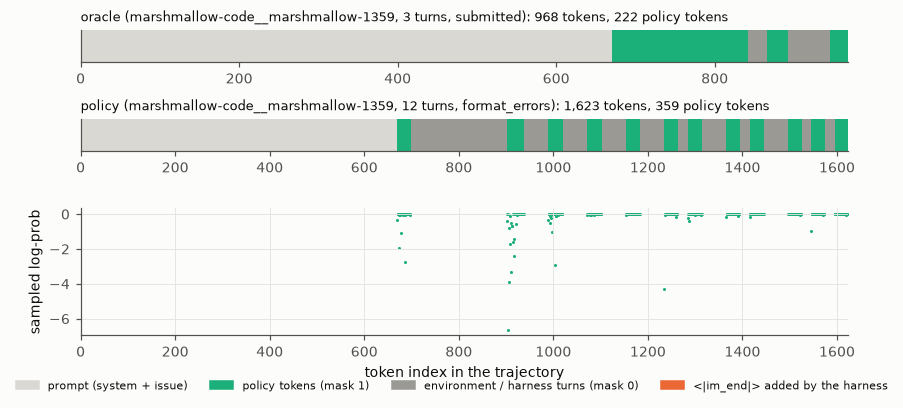

policy tokens with a sampled log-prob: 359 of 359; mean -0.122, share below -2: 1.9%; oracle log-probs present: False


In [19]:
step_dir = sorted(S8_TRAJ.glob("step-*"))[-1]
pick = lambda kind: sorted(step_dir.glob(f"{DEMO_TASK}__{kind}*.json*")) or sorted(step_dir.glob(f"*__{kind}*.json*"))
oracle_tr = load_json(pick("oracle")[0])
pols = [load_json(p) for p in pick("policy")]
policy_tr = max((p for p in pols if p["n_tokens"] <= 4000), key=lambda p: len(p["turns"]), default=pols[0])
fig = plt.figure(figsize=(9, 3.6))
gs = fig.add_gridspec(3, 1, height_ratios=[0.5, 0.5, 2.0], hspace=0.9)
mask_strip(fig.add_subplot(gs[0]), oracle_tr["ids"], oracle_tr["mask"], f"oracle ({oracle_tr['task_id']}, {len(oracle_tr['turns'])} turns, {oracle_tr['exit_reason']})")
ax_p = fig.add_subplot(gs[1])
mask_strip(ax_p, policy_tr["ids"], policy_tr["mask"], f"policy ({policy_tr['task_id']}, {len(policy_tr['turns'])} turns, {policy_tr['exit_reason']})")
ax = fig.add_subplot(gs[2], sharex=ax_p)
pos = [i for i, m in enumerate(policy_tr["mask"]) if m and policy_tr["logprobs"][i] is not None]
ax.scatter(pos, [policy_tr["logprobs"][i] for i in pos], s=4, color=C_POLICY, lw=0)
ax.set_ylabel("sampled log-prob"); ax.set_xlabel("token index in the trajectory")
fig.legend(handles=[Patch(color=c, label=n) for n, c in zip(KIND_NAMES, KIND_COLORS)], loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.06), fontsize=7.5)
show(fig, "s3_token_masks")
lp = np.array([policy_tr["logprobs"][i] for i in pos])
print(f"policy tokens with a sampled log-prob: {len(pos)} of {sum(policy_tr['mask'])}; mean {lp.mean():.3f}, "
      f"share below -2: {(lp < -2).mean():.1%}; oracle log-probs present: {any(v is not None for v in oracle_tr['logprobs'])}")

**Why keep sampled ids and not text?** The reference decodes each reply with `skip_special_tokens=True` and
`.strip()`. It then re-tokenises the whole conversation through the chat template (`build_masked`) to train. So the
tokens it trains on are not always the tokens that were sampled. The next cell measures this on the real replies of
the basic run's last step, in two ways:

1. Does *reference-style* re-tokenisation reproduce each reply's sampled ids?
2. Does re-rendering the whole conversation reproduce the trajectory?

In [20]:
if tok is None:
    skipped("re-tokenisation check", "needs the tokenizer (not on the headnode)")
else:
    rows = []
    for p in sorted(step_dir.glob("*.json*")):
        d = load_json(p)
        replies = [d["ids"][a:b] for a, b in mask_runs(d["mask"])]
        replies = [r[:-1] if r and r[-1] == IM_END else r for r in replies]
        differ = sum(tok(tok.decode(r, skip_special_tokens=True).strip(), add_special_tokens=False)["input_ids"] != r for r in replies)
        rows.append({"trajectory": p.stem, "replies": len(replies), "decode→strip→re-encode differs": differ,
                     "whole-conversation re-render reproduces ids": rerender_ids(tok, d["messages"], d["meta"]["protocol"])[: len(d["ids"])] == d["ids"]})
    rt = pd.DataFrame(rows)
    display(rt)
    print(f"{int(rt['decode→strip→re-encode differs'].sum())} of {int(rt['replies'].sum())} replies would be trained on "
          f"tokens that were not sampled; {int((~rt['whole-conversation re-render reproduces ids']).sum())} of {len(rt)} "
          "trajectories are not reproduced by a one-shot re-render. sarl trains on the recorded ids.")

,trajectory,replies,decode→strip→re-encode differs,whole-conversation re-render reproduces ids
0,marshmallow-code__marshmallow-1359__oracle7.json,3,0,True
1,marshmallow-code__marshmallow-1359__policy0.json,1,0,True
2,marshmallow-code__marshmallow-1359__policy1.json,3,0,True
3,marshmallow-code__marshmallow-1359__policy2.json,1,0,True
4,marshmallow-code__marshmallow-1359__policy3.json,3,0,True
5,marshmallow-code__marshmallow-1359__policy4.json,12,0,True
6,marshmallow-code__marshmallow-1359__policy5.json,2,0,True
7,marshmallow-code__marshmallow-1359__policy6.json,2,0,True
8,sqlfluff__sqlfluff-1625__oracle7.json,3,0,True
9,sqlfluff__sqlfluff-1625__policy0.json,1,0,True


1 of 102 replies would be trained on tokens that were not sampled; 3 of 16 trajectories are not reproduced by a one-shot re-render. sarl trains on the recorded ids.


### 3.4 One live rollout: vLLM policy + apptainer sandbox *(node08, needs `make -C swe-bench serve`)*

The diagram's inner loop, for real: the served Qwen2.5-Coder-0.5B plays one episode per protocol on the training task.
`/v1/completions` takes a token-id prompt and returns the sampled `token_ids`, including the `<|im_end|>` stop token,
plus `token_logprobs`. That is what keeps the harness token-exact.

In [21]:
if not (VLLM_OK and tok is not None):
    skipped("live rollout", f"needs node08, {DEMO_SIF.name}, the tokenizer, and vLLM at {SERVE_URL} (host={HOST}, sandbox={SANDBOX_OK}, served={SERVED})")
else:
    model_name = "policy" if "policy" in SERVED else SERVED[0]
    rows = []
    for proto in PROTOCOLS:
        with ApptainerEnv(DEMO_SIF, command_timeout=60) as env:
            tr = run_episode(VLLMPolicy(SERVE_URL, model_name, Sampling()), env, train_t, ChatFormat(tok, tools_for(proto)),
                             Limits(max_turns=6, max_context_tokens=8192, max_new_tokens=512), policy_name=model_name, protocol=proto)
        LIVE[proto] = tr
        pol_lp = [v for v, m in zip(tr.logprobs, tr.mask) if m]
        rows.append({"protocol": proto, "served model": model_name, "exit": tr.exit_reason, "turns": len(tr.turns),
                     "valid actions": sum("command" in t for t in tr.turns), "format errors": tr.n_format_errors,
                     "replies closed by <|im_end|>": sum(t["closed"] for t in tr.turns), "tokens": tr.n_tokens,
                     "policy tokens": tr.n_assistant_tokens, "all have log-probs": all(v is not None for v in pol_lp),
                     "patch chars": len(tr.patch), "wall s": tr.wall_s})
    display(pd.DataFrame(rows))
    for proto, tr in LIVE.items():
        print(f"---- {proto}: first reply ----\n{clip(tr.messages[2]['content'], 600)}\n")

,protocol,served model,exit,turns,valid actions,format errors,replies closed by <|im_end|>,tokens,policy tokens,all have log-probs,patch chars,wall s
0,tool_call,policy,format_errors,3,0,3,3,1186,206,True,0,0.97
1,backticks,policy,submitted,1,1,0,1,684,14,True,0,0.62


---- tool_call: first reply ----
Let's fix the issue described below in the repository at `/testbed`.

To fix the issue of `DateTime` fields not being used as inner fields of container fields like `List` or `Tuple`, we need to ensure that the `DateTime` field inherits from the `Time` field. This is because the `Time` and `DateTime` fields are meant to be used within list or tuple contexts and should inherit from `Time` for consis
[... 170 chars elided ...]
e()

s = MySchema()
```

This change ensures that the `DateTime` field is inheriting from the `Time` field, which resolves the issue of `DateTime` not being used as an inner field of container fields.

---- backticks: first reply ----
```bash
echo COMPLETE_TASK_AND_SUBMIT_FINAL_OUTPUT
```



## §4 · The reward

The diagram's REWARD box runs once, at episode end: `git checkout -- . && git clean -fd; git apply
submitted_patch.txt; bash run_tests.sh → r`. As the diagram puts it, "tree wiped — only the patch is replayed"
(lecture 0:35–0:36). `sarl.reward.grade` does the same, a little more strictly:

1. **A fresh container from the same image.** This throws away the rollout's instance, so anything the agent changed
   outside the repo is gone too: pip installs, `/tmp`, the conda env.
2. **The apply chain.** `git apply`, then `git apply --reject`, then `patch --fuzz=5`, resetting the tree between
   attempts.
3. **The task's `eval.sh`.** It installs the package, checks the test files out at `base_commit`, applies
   `test_patch`, and runs the tests between two markers.
4. **The official log parser.** It uses `swebench==5.0.2`, which lives in its own node-local venv so it never
   re-resolves the shared CUDA stack.

The reward is binary: **1 iff every FAIL_TO_PASS test passes and every PASS_TO_PASS test still passes.** The
reference could not run tests in a notebook, so it uses `reward_random`. That is a deliberately leaky proxy: no patch
scores 0, and any patch scores U(0,1) (lecture 1:40).

In [22]:
print("==== apply chain (runs inside a fresh container, --network none; /sarl_in holds patch.diff and eval.sh, READ-ONLY) ====")
print(APPLY_CHAIN.strip())
es = re.sub(r"(<<'(EOF_\d+)'\n)(.*?)(\n\2)", lambda m: f"{m.group(1)}[... test_patch: {m.group(3).count(chr(10)) + 1} lines, hidden from the agent ...]{m.group(4)}",
            train_t.eval_script, flags=re.S)
print(f"\n==== eval.sh for {train_t.instance_id} (the dev row's eval_script; test_patch body elided) ====")
print(es)

==== apply chain (runs inside a fresh container, --network none; /sarl_in holds patch.diff and eval.sh, READ-ONLY) ====
cd /testbed
ok=0
for c in "git apply --verbose" "git apply --verbose --reject" "patch --batch --fuzz=5 -p1 -i"; do
    if $c /sarl_in/patch.diff; then ok=1; echo ">>>>> Applied Patch ($c)"; break; fi
    git checkout -- . >/dev/null 2>&1; git clean -fd >/dev/null 2>&1
done
if [ "$ok" != 1 ]; then echo ">>>>> Patch Apply Failed"; exit 1; fi
bash /sarl_in/eval.sh

==== eval.sh for marshmallow-code__marshmallow-1359 (the dev row's eval_script; test_patch body elided) ====
#!/bin/bash
set -uxo pipefail
source /opt/miniconda3/bin/activate
conda activate testbed
cd /testbed
git config --global --add safe.directory /testbed
cd /testbed
git status
git show
git -c core.fileMode=false diff b40a0f4e33823e6d0f341f7e8684e359a99060d1
source /opt/miniconda3/bin/activate
conda activate testbed
python -m pip install -e '.[dev]'
git checkout b40a0f4e33823e6d0f341f7e8684e359a99060d1 tes

In [23]:
if not GRADER_OK:
    skipped("grading", f"needs node08, {DEMO_SIF.name} and the grader venv {GRADER_VENV} (host={HOST})")
else:
    from sarl.reward import grade
    target = re.search(r"^diff --git a/(\S+)", train_t.patch, re.M).group(1)
    with ApptainerEnv(DEMO_SIF) as env:                      # a valid patch to the right file that fixes nothing
        env.run(f"echo '# unrelated edit' >> {target}")
        wrong = env.patch()
    cases = {"gold patch": train_t.patch, "empty patch": "", "wrong patch (comment appended to the right file)": wrong}
    if SANDBOX_PATCH:
        cases["§2 sandbox edit"] = SANDBOX_PATCH
    cases.update({f"§3 live rollout ({p})": tr.patch for p, tr in LIVE.items() if tr.patch.strip()})
    rows = []
    for name, patch in cases.items():
        g = GRADES[name] = grade(train_t, patch, sif=DEMO_SIF, run_empty=True, keep=(name == "gold patch"))
        rows.append({"candidate": name, "patch chars": len(patch), "applied": g.applied, "F2P": f"{g.f2p_passed}/{g.f2p_total}",
                     "P2P": f"{g.p2p_passed}/{g.p2p_total}", "reward": g.reward, "seconds": round(g.seconds, 1)})
    display(pd.DataFrame(rows))

,candidate,patch chars,applied,F2P,P2P,reward,seconds
0,gold patch,483,True,1/1,76/76,1.0,3.6
1,empty patch,0,True,0/1,76/76,0.0,3.8
2,wrong patch (comment appended to the right file),258,True,0/1,76/76,0.0,3.7
3,§2 sandbox edit,491,True,1/1,76/76,1.0,3.7


In [24]:
if GRADES:
    wd = Path(GRADES["gold patch"].workdir)  # kept for this demo; grading deletes its workdir by default
    used = (wd / "in" / "eval.sh").read_text()  # in/ is bound read-only into the container
    print("eval.sh the grader generated (make_test_spec) == the dataset row's eval_script:", used.strip() == train_t.eval_script.strip())
    print("(make_test_spec adds the SWEBENCH_TEST_EXIT_CODE bookkeeping lines, so exact equality is not expected)")
    log = (wd / "host" / "test_output.txt").read_text(errors="replace")  # host-only: the container never sees it
    applied = [l for l in log.splitlines() if l.startswith(">>>>> Applied Patch")]
    body = log.split(">>>>> Start Test Output")[-1].split(">>>>> End Test Output")[0].strip().splitlines()
    print(applied[:1], "\n\ngold run, last lines of the test output:\n" + "\n".join(body[-8:]))

eval.sh the grader generated (make_test_spec) == the dataset row's eval_script: False
(make_test_spec adds the SWEBENCH_TEST_EXIT_CODE bookkeeping lines, so exact equality is not expected)
['>>>>> Applied Patch (git apply --verbose)'] 

gold run, last lines of the test output:
PASSED tests/test_fields.py::TestDictNested::test_dict_nested_only_exclude_dump_only_load_only_propagated_to_nested[dump_only]
PASSED tests/test_fields.py::TestDictNested::test_dict_nested_only_exclude_dump_only_load_only_propagated_to_nested[load_only]
PASSED tests/test_fields.py::TestDictNested::test_dict_nested_only_and_exclude_merged_with_nested[only-expected0]
PASSED tests/test_fields.py::TestDictNested::test_dict_nested_only_and_exclude_merged_with_nested[exclude-expected1]
PASSED tests/test_fields.py::TestDictNested::test_dict_nested_partial_propagated_to_nested
======================== 77 passed, 1 warning in 0.08s =========================
+ SWEBENCH_TEST_EXIT_CODE=0
+ : '


**The pool gate (S5).** A task is only usable if its gold patch can score 1 and its empty patch scores 0 under *our*
sandbox. `scripts/pool_gate.py` grades both for all 8 pool tasks, and all 8 pass, at about 5–13 s per grade.

The gate did not pass the first time. `--containall` implies `--cleanenv`, which leaves `LANG=C` inside the container,
and the Python 3.6 testbeds then use an ASCII filesystem encoding. As a result, `pydicom-811`'s `testUTF8FileName`
failed **even for the gold patch**. The fix was `APPTAINERENV_LANG/LC_ALL=C.UTF-8`. The basic run's steps 8–9 still
had the bug; §5 shows its fingerprint. This table is read from disk:

In [25]:
gate = load_json(EXPERIMENTS / "pool-gate.json")
pd.DataFrame([{"task": g["instance_id"], "gate ok": g["ok"], "gold reward": g["gold_reward"], "empty reward": g["empty_reward"],
               "F2P (gold)": "{}/{}".format(*g["f2p"]), "P2P (gold)": "{}/{}".format(*g["p2p"]),
               "failing under apptainer": ", ".join(g["failing_tests"]) or "none"} for g in gate])

,task,gate ok,gold reward,empty reward,F2P (gold),P2P (gold),failing under apptainer
0,pylint-dev__astroid-946,True,1.0,0.0,1/1,155/155,none
1,marshmallow-code__marshmallow-1359,True,1.0,0.0,1/1,76/76,none
2,pydicom__pydicom-811,True,1.0,0.0,1/1,85/85,none
3,pylint-dev__astroid-1614,True,1.0,0.0,1/1,9/9,none
4,sqlfluff__sqlfluff-1625,True,1.0,0.0,1/1,64/64,none
5,pydicom__pydicom-1256,True,1.0,0.0,1/1,22/22,none
6,pydicom__pydicom-1694,True,1.0,0.0,1/1,26/26,none
7,pylint-dev__astroid-1268,True,1.0,0.0,1/1,91/91,none


## §5 · Group-relative advantages

$$A_i = \frac{r_i - \operatorname{mean}(r)}{\operatorname{std}(r) + \varepsilon}, \qquad \text{std biased } (\div G),\ \varepsilon = 10^{-4}$$

This is the reference's formula (lecture 1:46), implemented in `sarl.grpo.group_advantages`. There is no critic: **the
other rollouts of the same task are the baseline.** G rollouts start from the same prompt at temperature 1.0 and differ
only in the policy's sampling. The worked example is the reference's group: 7 model rollouts that fail, plus 1 oracle
that succeeds.

In [26]:
r = np.array([0.0] * 7 + [1.0])
A = group_advantages(r)
ref = (r - r.mean()) / (r.std() + 1e-4)          # the reference's torch line with unbiased=False, in numpy
display(pd.DataFrame({"rollout": range(8), "kind": ["policy"] * 7 + ["oracle"], "reward": r, "advantage": A.round(4)}))
print(f"sum of advantages = {A.sum():+.1e} (a baseline, not a bonus); equals the reference formula: {np.allclose(A, ref)}")
print(f"binary rewards, k of G succeed: A_success = +sqrt((G-k)/k), A_fail = -sqrt(k/(G-k)) → k=1, G=8: {np.sqrt(7):+.4f} / {-np.sqrt(1/7):+.4f}")

,rollout,kind,reward,advantage
0,0,policy,0.0,-0.3779
1,1,policy,0.0,-0.3779
2,2,policy,0.0,-0.3779
3,3,policy,0.0,-0.3779
4,4,policy,0.0,-0.3779
5,5,policy,0.0,-0.3779
6,6,policy,0.0,-0.3779
7,7,oracle,1.0,2.6450


sum of advantages = -2.2e-16 (a baseline, not a bonus); equals the reference formula: True
binary rewards, k of G succeed: A_success = +sqrt((G-k)/k), A_fail = -sqrt(k/(G-k)) → k=1, G=8: +2.6458 / -0.3780


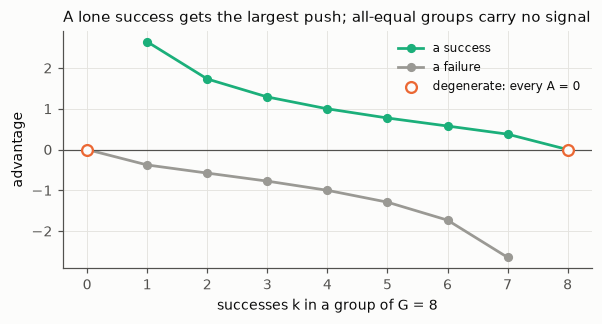

In [27]:
G = 8
ks = np.arange(0, G + 1)
a_succ = [group_advantages([1.0] * k + [0.0] * (G - k))[0] if k else np.nan for k in ks]
a_fail = [group_advantages([1.0] * k + [0.0] * (G - k))[-1] if k < G else np.nan for k in ks]
fig, ax = plt.subplots(figsize=(6.2, 2.8))
ax.plot(ks, a_succ, marker="o", color=C_POLICY, label="a success")
ax.plot(ks, a_fail, marker="o", color=C["gray"], label="a failure")
ax.scatter([0, G], [0, 0], s=50, facecolor=SURFACE, edgecolor=C_ORACLE, lw=1.5, zorder=3, label="degenerate: every A = 0")
ax.axhline(0, color=INK2, lw=0.8); ax.set_xticks(ks)
ax.set_xlabel(f"successes k in a group of G = {G}"); ax.set_ylabel("advantage"); ax.legend(loc="upper right")
ax.set_title("A lone success gets the largest push; all-equal groups carry no signal")
show(fig, "s5_advantage_vs_k")

**Degenerate groups.** When every rollout scores the same, `std` is 0, every numerator is 0, and every advantage is 0.
`ε` is what makes that 0 and not NaN. The three sources treat these groups differently:

- **The lecture** says to throw them out (2:00).
- **The reference code** keeps them. It prints a warning and still takes the step, which is a no-op there only because
  it is the first step.
- **sarl** skips them (`advantage.skip_degenerate: true`) and counts them. §6 shows why skipping is the only true
  no-op in a multi-step run.

These are the real groups of the basic run (2 tasks × G=8 per step, 7 policy rollouts + 1 oracle each):

In [28]:
steps = list(read_jsonl(S8 / "metrics.jsonl"))
grp = pd.DataFrame([{"step": s["step"], "task": g["task"], "rewards": " ".join(f"{x:g}" for x in g["rewards"][:-1]) + " | " + f"{g['rewards'][-1]:g}",
                     "A(policy)": g["adv"][0], "A(oracle)": g["adv"][-1], "degenerate": g["degenerate"],
                     "recomputed = logged": bool(np.allclose(group_advantages(g["rewards"]), g["adv"], atol=1e-3))}
                    for s in steps for g in s["groups"]])
display(grp)
print(f"{len(grp)} groups: {int((~grp['degenerate']).sum())} informative, {int(grp['degenerate'].sum())} degenerate "
      f"({', '.join(sorted(set(grp.loc[grp['degenerate'], 'task'])))}: the oracle's gold patch also scored 0, the LANG=C bug of §4)")

,step,task,rewards,A(policy),A(oracle),degenerate,recomputed = logged
0,1,pydicom__pydicom-1694,0 0 0 0 0 0 0 | 1,-0.3779,2.645,False,True
1,1,pylint-dev__astroid-1268,0 0 0 0 0 0 0 | 1,-0.3779,2.645,False,True
2,2,pydicom__pydicom-1694,0 0 0 0 0 0 0 | 1,-0.3779,2.645,False,True
3,2,pylint-dev__astroid-946,0 0 0 0 0 0 0 | 1,-0.3779,2.645,False,True
4,3,sqlfluff__sqlfluff-1625,0 0 0 0 0 0 0 | 1,-0.3779,2.645,False,True
5,3,pylint-dev__astroid-1268,0 0 0 0 0 0 0 | 1,-0.3779,2.645,False,True
6,4,pylint-dev__astroid-1268,0 0 0 0 0 0 0 | 1,-0.3779,2.645,False,True
7,4,pylint-dev__astroid-1614,0 0 0 0 0 0 0 | 1,-0.3779,2.645,False,True
8,5,sqlfluff__sqlfluff-1625,0 0 0 0 0 0 0 | 1,-0.3779,2.645,False,True
9,5,pylint-dev__astroid-1614,0 0 0 0 0 0 0 | 1,-0.3779,2.645,False,True


20 groups: 20 informative, 0 degenerate (: the oracle's gold patch also scored 0, the LANG=C bug of §4)


## §6 · The update

This is the reference's loss, "REINFORCE with a group baseline" (lecture 1:56–1:59). For each trajectory it takes the
**mean** log-prob of that trajectory's policy tokens (mask 1), weighted by the trajectory's advantage:

$$\mathcal{L}(\theta) = -\frac{1}{N}\sum_{i=1}^{N} A_i \cdot \frac{1}{|T_i|}\sum_{t \in T_i} \log \pi_\theta(a_t \mid s_t), \qquad T_i = \{t : \text{mask}_t = 1\}$$

- **Masking.** Prompt and observation tokens carry no gradient. The environment wrote them, so crediting them is
  meaningless (lecture 1:31–1:39).
- **Equal weight per trajectory.** The per-trajectory mean gives every trajectory the same weight, whatever its
  length. Other normalisations exist (token-mean, or a constant) and are a phase-2 knob.
- **The step.** One AdamW step, with gradient-norm clipping at 1.0.
- **LoRA.** r=8, α=16 on q/k/v/o, with the adapter kept in fp32. The lecture uses LoRA "purely because" fp16 Adam
  second moments underflow (≈1:47). LoRA starts as the identity (B = 0), so the policy that sampled the group is
  exactly the one being updated.
- **Log-probs.** `LoRATrainer.token_logprobs` computes them with a chunked log-softmax over only the supervised
  positions. A 16k-token trajectory's full logits would be 16k × 152k floats.

The demo below runs the reference's cell-42 table on a **tiny random Qwen2** (2 layers, vocab 64, CPU; the same model
as `tests/test_swe_grpo.py`). It uses a large learning rate so the move is visible.

In [29]:
if not CPU_DEMO_OK:
    skipped("tiny-model update demo", "no model training on the headnode, even a tiny one")
else:
    import torch
    from transformers import Qwen2Config, Qwen2ForCausalLM
    from sarl.grpo import LoRATrainer, TrainConfig
    torch.set_num_threads(4)

    def tiny_qwen(seed=0):
        torch.manual_seed(seed)
        return Qwen2ForCausalLM(Qwen2Config(vocab_size=64, hidden_size=32, intermediate_size=64, num_hidden_layers=2, num_attention_heads=4,
                                            num_key_value_heads=2, max_position_embeddings=256, tie_word_embeddings=True)).float()

    g = torch.Generator().manual_seed(0)
    mask = [0] * 12 + [1] * 12 + [0] * 10 + [1] * 14          # prompt | reply | observation | reply
    group = [(torch.randint(0, 64, (len(mask),), generator=g).tolist(), mask) for _ in range(8)]
    rewards = [0.0] * 7 + [1.0]
    adv = group_advantages(rewards)
    tr6 = LoRATrainer("tiny", model=tiny_qwen(), cfg=TrainConfig(lr=5e-2, lora_r=4, lora_alpha=8), device="cpu")
    h0 = tr6.adapter_hash()
    before = [tr6.logprobs_nograd(i, m).mean() for i, m in group]
    out = tr6.step([(i, m, a) for (i, m), a in zip(group, adv)])
    after = [tr6.logprobs_nograd(i, m).mean() for i, m in group]
    gain = float(np.mean([a * (x - y) for a, x, y in zip(adv, after, before)]))
    print(f"trainable (LoRA) params {tr6.n_trainable:,}; loss {out['loss']:+.5f}; grad_norm {out['grad_norm']:.4f}; "
          f"supervised tokens {out['tokens']}; adapter {h0} → {tr6.adapter_hash()}")
    print(f"surrogate J = mean_i A_i·mean log p: gain after the step = {gain:+.5f} (the update ascends J)")
    display(pd.DataFrame({"rollout": range(8), "reward": rewards, "advantage": adv.round(3), "sup_tokens": [sum(m[1:]) for _, m in group],
                          "logp_before": np.round(before, 4), "logp_after": np.round(after, 4), "delta": np.round(np.subtract(after, before), 5)}))

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


trainable (LoRA) params 1,792; loss +0.00052; grad_norm 0.0835; supervised tokens 208; adapter eac9653ab44d → 2b56554d4ff2
surrogate J = mean_i A_i·mean log p: gain after the step = +0.03199 (the update ascends J)


,rollout,reward,advantage,sup_tokens,logp_before,logp_after,delta
0,0,0.0,-0.378,26,-4.1377,-4.1243,0.01347
1,1,0.0,-0.378,26,-4.1371,-4.1450,-0.00795
2,2,0.0,-0.378,26,-4.1701,-4.1940,-0.02393
3,3,0.0,-0.378,26,-4.1848,-4.1861,-0.00125
4,4,0.0,-0.378,26,-4.1757,-4.1625,0.01321
5,5,0.0,-0.378,26,-4.1884,-4.1868,0.00165
6,6,0.0,-0.378,26,-4.2018,-4.2601,-0.05827
7,7,1.0,2.645,26,-4.1724,-4.0846,0.08774


Positive advantage pushes a trajectory's log-probability up, and negative advantage pushes it down. The rows share
parameters, so only the weighted sum J is guaranteed to rise for a small enough step. An individual row can still move
against its sign.

**Degenerate groups, measured.** Take the same trainer after its first step and give it a batch where every A = 0.
With zero gradients, a step would change nothing only if the optimizer had no state. AdamW, however, still applies
the momentum left over from the previous step, plus its decoupled weight decay. The reference's degenerate step was
a no-op only because it was the first step. In a multi-step loop, skipping is the only true no-op.

In [30]:
if CPU_DEMO_OK:
    fresh = LoRATrainer("tiny", model=tiny_qwen(), cfg=TrainConfig(lr=5e-2, lora_r=4, lora_alpha=8), device="cpu")
    b0 = [fresh.logprobs_nograd(i, m) for i, m in group]
    fresh.step([(i, m, 0.0) for i, m in group])
    first = max(float(np.abs(x - y).max()) for x, y in zip(b0, [fresh.logprobs_nograd(i, m) for i, m in group]))
    b1 = [tr6.logprobs_nograd(i, m) for i, m in group]
    o = tr6.step([(i, m, 0.0) for i, m in group])
    later = max(float(np.abs(x - y).max()) for x, y in zip(b1, [tr6.logprobs_nograd(i, m) for i, m in group]))
    display(pd.DataFrame([("A = 0 on a fresh adapter (the reference's case)", first), ("A = 0 after one real step (a multi-step loop)", later)],
                         columns=["zero-advantage step", "max |Δ log p| over all trained tokens"]))

,zero-advantage step,max |Δ log p| over all trained tokens
0,A = 0 on a fresh adapter (the reference's case),0.000000
1,A = 0 after one real step (a multi-step loop),0.197015


## §7 · The loop, run: the basic GRPO run (gate S8)

The final basic run (`runs/s8-basic-v3b`, config `configs/basic_run.yaml`; earlier runs in `experiments/runs/`) ran the
diagram end to end on node08:

- vLLM serves πθ on GPU0, and the trainer holds the LoRA on GPU1.
- Each step picks 2 pool tasks and runs **G = 8 rollouts per task (7 policy + 1 scripted gold-patch oracle)**, each in
  its own apptainer sandbox.
- Every candidate patch is graded by real tests.
- The trainer computes the advantages and takes one LoRA step (lr 1e-5, r=8 on q/k/v/o).
- The new adapter is then loaded into vLLM at runtime (`POST /v1/load_lora_adapter`), and the next step samples from
  πθ′.
- Protocol: `backticks`. 10 steps in all.

The run logs four diagnostics per step:

- **objective gain**, J_after − J_before on the trained batch: did the update go uphill?
- **served_dlogp_vs_base**, the mean |log p_served − log p_base| of a fixed probe sequence, read from vLLM's
  `prompt_logprobs` after the sync. This proves the server now serves πθ′ and not the base model.
- **train-inference mismatch**, |log p_trainer − log p_vLLM| on the sampled tokens *before* the update, when both
  hold the same weights (lecture 2:31–2:34).
- **step time**, split into rollouts, grading, and the rest (update + sync).

In [31]:
m = pd.DataFrame([{"step": s["step"], "tasks": ", ".join(t.split("__")[1] for t in s["tasks"]), "policy reward": s["policy_reward_mean"],
                   "policy resolved": s["policy_resolved"], "oracle resolved": s["oracle_resolved"], "degenerate groups": s["n_degenerate_groups"],
                   "trained trajs": s["n_train"], "dropped overlong": s["dropped_overlong"], "loss": (s["update"] or {}).get("loss"),
                   "grad norm": (s["update"] or {}).get("grad_norm"), "objective gain": s["objective_gain"],
                   "oracle Δlogp": np.mean(s["oracle_dlogp"]) if s["oracle_dlogp"] else np.nan, "policy Δlogp": s["policy_dlogp_mean"],
                   "served dlogp vs base": (s["sync"] or {}).get("served_dlogp_vs_base"),
                   "mismatch mean": (s["mismatch"] or {}).get("mean"), "mismatch p99": (s["mismatch"] or {}).get("p99"),
                   "mismatch max": (s["mismatch"] or {}).get("max"), "valid action rate": s.get("policy_valid_action_rate"),
                   "mean turns": s.get("policy_mean_turns"), "rollouts s": s["seconds"]["rollouts"], "grading s": s["seconds"]["grading"],
                   "total s": s["seconds"]["total"]} for s in steps])
print({k: cfg8.get(k) for k in ("model", "protocol", "steps", "tasks_per_step", "group_size", "oracle_per_group", "sampling", "train", "advantage")})
m.round(4)

{'model': 'Qwen/Qwen2.5-Coder-0.5B-Instruct', 'protocol': 'backticks', 'steps': 10, 'tasks_per_step': 2, 'group_size': 8, 'oracle_per_group': 1, 'sampling': {'temperature': 1.0, 'top_p': 1.0, 'top_k': -1, 'repetition_penalty': 1.0}, 'train': {'lr': 1e-05, 'lora_r': 8, 'lora_alpha': 16, 'targets': ['q_proj', 'k_proj', 'v_proj', 'o_proj'], 'clip': 1.0, 'max_train_tokens': 8192, 'chunk': 1024}, 'advantage': {'eps': 0.0001, 'skip_degenerate': True}}


,step,tasks,policy reward,policy resolved,oracle resolved,degenerate groups,trained trajs,dropped overlong,loss,grad norm,...,policy Δlogp,served dlogp vs base,mismatch mean,mismatch p99,mismatch max,valid action rate,mean turns,rollouts s,grading s,total s
0,1,"pydicom-1694, astroid-1268",0.0,0,2,0,15,1,0.5150,0.6338,...,-0.0007,0.0251,0.0018,0.0575,0.1894,0.8750,10.6429,1807.0,5.1,1818.0
1,2,"pydicom-1694, astroid-946",0.0,0,2,0,16,0,0.4456,0.6340,...,-0.0009,0.0234,0.0071,0.1015,0.1818,0.9571,6.5714,8.5,5.6,18.3
2,3,"sqlfluff-1625, astroid-1268",0.0,0,2,0,16,0,0.4750,0.5962,...,-0.0001,0.0276,0.0033,0.0825,0.3438,0.7440,8.6429,13.4,10.2,28.7
3,4,"astroid-1268, astroid-1614",0.0,0,2,0,16,0,0.3943,0.6161,...,-0.0003,0.0237,0.0066,0.1066,0.4009,0.9248,6.7857,13.7,5.4,24.6
4,5,"sqlfluff-1625, astroid-1614",0.0,0,2,0,16,0,0.4084,0.6295,...,-0.0006,0.0241,0.0052,0.1007,0.2943,0.7726,7.4286,14.4,10.1,29.3
5,6,"pydicom-1256, sqlfluff-1625",0.0,0,2,0,15,1,0.4614,0.6531,...,0.0017,0.0220,0.0074,0.1139,0.2897,0.9060,12.5000,22.9,10.5,38.8
6,7,"astroid-1614, sqlfluff-1625",0.0,0,2,0,16,0,0.3981,0.6224,...,-0.0010,0.0196,0.0077,0.1058,0.2911,0.7869,7.5714,13.5,10.3,28.4
7,8,"pydicom-811, astroid-1268",0.0,0,2,0,16,0,0.4428,0.5579,...,-0.0007,0.0229,0.0051,0.1067,0.2382,0.9857,13.2143,27.1,5.2,39.0
8,9,"pydicom-811, pydicom-1694",0.0,0,2,0,16,0,0.4468,0.5760,...,-0.0007,0.0257,0.0036,0.0839,0.2322,0.8740,11.3571,16.0,4.3,27.7
9,10,"marshmallow-1359, sqlfluff-1625",0.0,0,2,0,14,2,0.4974,0.7194,...,-0.0010,0.0216,0.0027,0.0821,0.1605,0.8417,6.8571,31.1,10.4,45.8


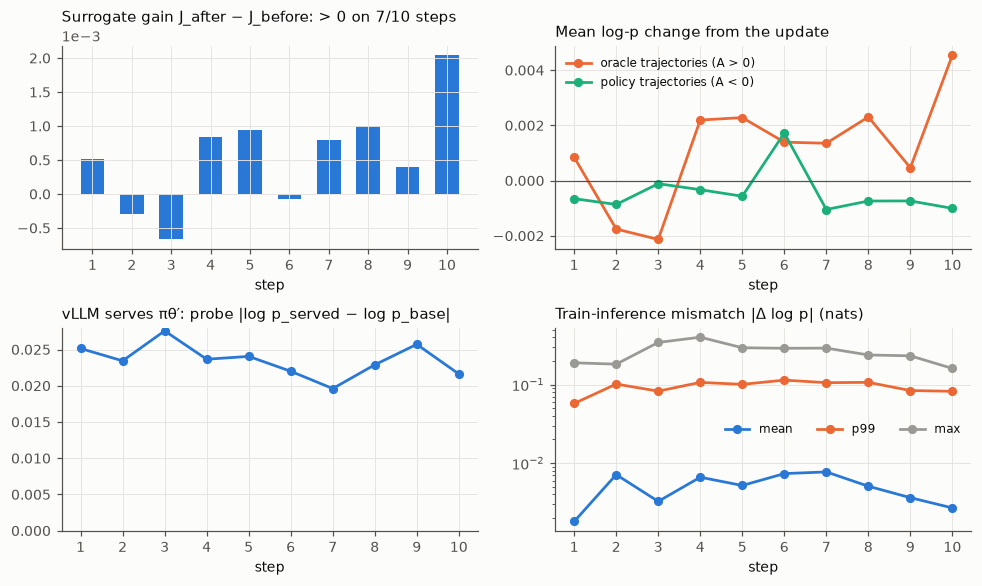

In [32]:
fig, axs = plt.subplots(2, 2, figsize=(9, 5.4))
x = m["step"]
ax = axs[0, 0]; ax.bar(x, m["objective gain"], color=C["blue"], width=0.6)
ax.set_title(f"Surrogate gain J_after − J_before: > 0 on {int((m['objective gain'] > 0).sum())}/{len(m)} steps")
ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
ax = axs[0, 1]
ax.plot(x, m["oracle Δlogp"], marker="o", color=C_ORACLE, label="oracle trajectories (A > 0)")
ax.plot(x, m["policy Δlogp"], marker="o", color=C_POLICY, label="policy trajectories (A < 0)")
ax.axhline(0, color=INK2, lw=0.8); ax.set_title("Mean log-p change from the update"); ax.legend(loc="upper left")
ax = axs[1, 0]; ax.plot(x, m["served dlogp vs base"], marker="o", color=C["blue"])
ax.set_ylim(0, None); ax.set_title("vLLM serves πθ′: probe |log p_served − log p_base|")
ax = axs[1, 1]
for col, c in (("mismatch mean", C["blue"]), ("mismatch p99", C_ORACLE), ("mismatch max", C["gray"])):
    ax.plot(x, m[col], marker="o", color=c, label=col.replace("mismatch ", ""))
ax.set_yscale("log"); ax.set_title("Train-inference mismatch |Δ log p| (nats)"); ax.legend(loc="center right", ncol=3)
for a in axs.flat:
    a.set_xticks(x); a.set_xlabel("step")
fig.tight_layout()
show(fig, "s7_update_and_sync")

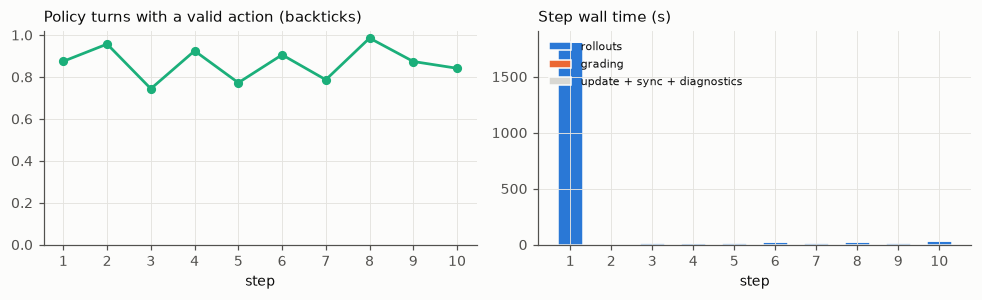

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(9, 2.8))
ax = axs[0]; ax.plot(x, m["valid action rate"], marker="o", color=C_POLICY)
ax.set_ylim(0, 1.02); ax.set_title("Policy turns with a valid action (backticks)")
ax = axs[1]
other = m["total s"] - m["rollouts s"] - m["grading s"]
ax.bar(x, m["rollouts s"], color=C["blue"], width=0.6, label="rollouts", edgecolor=SURFACE, lw=1)
ax.bar(x, m["grading s"], bottom=m["rollouts s"], color=C_ORACLE, width=0.6, label="grading", edgecolor=SURFACE, lw=1)
ax.bar(x, other, bottom=m["rollouts s"] + m["grading s"], color=C["light"], width=0.6, label="update + sync + diagnostics", edgecolor=SURFACE, lw=1)
ax.set_title("Step wall time (s)"); ax.legend(loc="upper left", fontsize=7.5)
for a in axs:
    a.set_xticks(x); a.set_xlabel("step")
fig.tight_layout()
show(fig, "s7_actions_and_time")

In [34]:
ro = pd.DataFrame([{"step": r["step"], "task": r["task"], "kind": r["kind"], "exit": r.get("exit_reason"), "turns": len(r.get("turns") or []),
                    "tokens": r.get("n_tokens"), "format errors": r.get("n_format_errors"), "patch": bool(r.get("patch")),
                    "applied": bool((r.get("grade") or {}).get("applied")), "reward": (r.get("grade") or {}).get("reward", 0.0),
                    "error": r.get("error")} for r in read_jsonl(S8 / "rollouts.jsonl")])
display(pd.crosstab(ro["kind"], ro["exit"], margins=True))
display(ro.groupby("kind").agg(rollouts=("reward", "size"), resolved=("reward", "sum"), mean_reward=("reward", "mean"),
                                mean_turns=("turns", "mean"), mean_tokens=("tokens", "mean"), nonempty_patches=("patch", "sum"),
                                applied_patches=("applied", "sum"), format_errors=("format errors", "sum"), crashed=("error", "count")).round(2))
pt = ro.pivot_table(index="task", columns="kind", values="reward", aggfunc=["sum", "size"])
pt.columns = [f"{k} {'resolved' if a == 'sum' else 'rollouts'}" for a, k in pt.columns]
display(pt.astype(int))
print(f"policy: {int(ro.loc[ro.kind == 'policy', 'reward'].sum())}/{int((ro.kind == 'policy').sum())} resolved; "
      f"objective gain > 0 on {int((m['objective gain'] > 0).sum())}/{len(m)} steps; served dlogp vs base "
      f"{m['served dlogp vs base'].min():.3f}–{m['served dlogp vs base'].max():.3f}; mismatch mean {m['mismatch mean'].min():.4f}–"
      f"{m['mismatch mean'].max():.4f}, p99 ≤ {m['mismatch p99'].max():.3f}, max ≤ {m['mismatch max'].max():.3f}")

exit,format_errors,max_turns,submitted,wall_clock,All
kind,,,,,
oracle,0,0,20,0,20
policy,17,52,70,1,140
All,17,52,90,1,160


,rollouts,resolved,mean_reward,mean_turns,mean_tokens,nonempty_patches,applied_patches,format_errors,crashed
kind,,,,,,,,,
oracle,20,20.0,1.0,3.00,892.40,20,20,0,0
policy,140,0.0,0.0,9.16,1761.23,3,2,96,0


,oracle resolved,policy resolved,oracle rollouts,policy rollouts
task,,,,
marshmallow-code__marshmallow-1359,1,0,1,7
pydicom__pydicom-1256,1,0,1,7
pydicom__pydicom-1694,3,0,3,21
pydicom__pydicom-811,2,0,2,14
pylint-dev__astroid-1268,4,0,4,28
pylint-dev__astroid-1614,3,0,3,21
pylint-dev__astroid-946,1,0,1,7
sqlfluff__sqlfluff-1625,5,0,5,35


policy: 0/140 resolved; objective gain > 0 on 7/10 steps; served dlogp vs base 0.020–0.028; mismatch mean 0.0018–0.0077, p99 ≤ 0.114, max ≤ 0.401


**Reading this honestly.** Qwen2.5-Coder-0.5B resolved **0 of 140** policy rollouts. That was expected: no SWE-bench
number for a 0.5B model has been published, and 7B models start near 2%. Most of its episodes submit almost
immediately, run into format errors, or wander until the turn budget runs out.

Every non-degenerate group's signal therefore comes from the **scripted oracle**. The oracle is off-policy and logged
as such. Each update raises the oracle trajectories' log-prob and lowers the policy's own, which is supervised
imitation of a gold patch expressed through the RL loss.

**What the run proves is the loop:**

- real sandboxes and real test rewards;
- grouped advantages;
- a LoRA update that increases the surrogate on every step;
- a server that demonstrably serves the updated weights after each sync;
- a small train-inference mismatch: mean ≈ 0.005–0.01 nats, and no token above 0.5.

**What it does not prove is learning.** The policy's own reward never moved. Real signal needs a policy that sometimes
solves pool tasks on its own: an SFT warm-up on the action format, or a larger model (lecture 2:50). The two
degenerate groups (pydicom-811, steps 8–9) are the LANG=C grading bug from §4, which was fixed after this run.

## §8 · The reference as published (gate S1, phase 1)

`scripts/phase1_reference.sh` runs the upstream script and the 44-cell notebook **as published** on node08 GPU1. The
only change is that the notebook's two `!pip` lines are dropped. The script uses G=6 model rollouts with no oracle; the
notebook uses 7 + the oracle. Both use `reward_random` and one LoRA step on the lecture's Verified task.
`sarl.phase1_summary` writes the numbers into `experiments/phase1-reference.json`, tagged `contaminates_eval`, and
nothing from it is reused. The rewards are the random proxy, so these numbers measure the plumbing, not the skill.

In [35]:
P1 = EXPERIMENTS / "phase1-reference.json"
runs1 = sorted((RUNS / "phase1").glob("2*")) if (RUNS / "phase1").exists() else []
if not P1.exists():
    print("PENDING — experiments/phase1-reference.json not written yet" + (f"; latest run dir {runs1[-1].name}" if runs1 else ""))
else:
    p1 = load_json(P1)
    latest = runs1[-1].name if runs1 else None
    print(f"summary of {Path(p1['run_dir']).name} on {p1.get('host')} (upstream {p1.get('upstream_sha', '')[:8]}, task {p1.get('task')}, "
          f"contaminates_eval={p1.get('contaminates_eval')}); versions {p1.get('versions')}")
    if latest and latest != Path(p1["run_dir"]).name:
        print(f"NOTE: a newer phase-1 run exists ({latest}); this summary is from an earlier attempt and will be overwritten when it finishes.")
    rows = []
    for part in ("script", "notebook"):
        s = p1.get(part)
        if not s:
            rows.append({"part": part, "status": "not in summary"}); continue
        rw = [x["reward"] for x in s.get("rollouts", [])]
        rows.append({"part": part, "status": "complete" if rw else "INCOMPLETE (no rollouts parsed)", "rollouts": len(rw),
                     "with patch": sum(x["patch"] for x in s.get("rollouts", [])), "mean reward": s.get("mean_reward"), "std": s.get("std_reward"),
                     "degenerate": s.get("degenerate_group"), "loss": s.get("loss"), "grad norm": s.get("grad_norm"),
                     "trainable params": s.get("trainable_params"), "wall clock": s.get("wall_clock"),
                     "cells with errors": s.get("cells_with_errors")})
    display(pd.DataFrame(rows))
    for part in ("script", "notebook"):
        s = p1.get(part) or {}
        if s.get("rollouts"):
            display(pd.DataFrame(s["rollouts"]).assign(part=part))
        elif s:
            print(f"{part} output tail:\n{clip(s.get('tail') or s.get('outputs_tail') or '', 800)}")
    rev = Path(p1["run_dir"]) / "revisions.txt"
    if rev.exists():
        print("\nrevision check (upstream loads `main`, we pin):\n" + rev.read_text())

summary of 20260924-012324 on node08 (upstream 8cddfb60, task astropy__astropy-12907, contaminates_eval=True); versions {'torch': '2.11.0+cu128', 'transformers': '5.14.1', 'peft': '0.19.1', 'cuda': True}


,part,status,rollouts,with patch,mean reward,std,degenerate,loss,grad norm,trainable params,wall clock,cells with errors
0,script,complete,6,2,0.151,0.239,False,-0.04545,0.7800,1081344,0:37.86,None
1,notebook,complete,8,3,0.119,0.214,False,-0.05207,0.6067,1081344,NaN,[]


,i,commands,patch,reward,part
0,0,4,False,0.000,script
1,1,4,False,0.000,script
2,2,3,True,0.637,script
3,3,4,False,0.000,script
4,4,4,True,0.270,script
5,5,4,False,0.000,script


,i,commands,patch,reward,part
0,0,4,False,0.000,notebook
1,1,3,True,0.637,notebook
2,2,4,False,0.000,notebook
3,3,4,True,0.270,notebook
4,4,4,False,0.000,notebook
5,5,3,False,0.000,notebook
6,6,3,False,0.000,notebook
7,8,4,True,0.041,notebook



revision check (upstream loads `main`, we pin):
revision ok  models--Qwen--Qwen2.5-Coder-0.5B-Instruct main=ea3f2471cf1b1f0db85067f1ef93848e38e88c25
revision ok  datasets--princeton-nlp--SWE-bench_Verified main=c104f840cc67f8b6eec6f759ebc8b2693d585d4a



## §9 · Lecture ↔ code

The timestamps come from the lecture's auto-generated transcript and were checked against it (research notes of
2026-09-24).

| time | lecture | reference (`utils.py` / notebook cell) | `sarl` |
|---|---|---|---|
| 0:14–0:15 | trains on eval data "for illustrative purposes" | cell 3: `princeton-nlp/SWE-bench_Verified` | trains on the **dev** split; `contamination_report`; the phase-1 replica is tagged `contaminates_eval` |
| 0:18–0:25 | task fields; astropy-12907 (F2P 2, P2P 13) | cells 3–12 | `tasks.Task`, `sarl task <id>`; §1 |
| 0:30–0:37 | the diagram: agent = harness + policy; container env; tool-call action; return code + output | cell 13 | `harness`, `protocol`, `env.apptainer`; §0 |
| 0:34–0:35 | exits: max turns, submit sentinel, context, wall clock | `run_agent`: fixed turns only | `Limits` → `exit_reason`; §3.2 |
| 0:35–0:36 | clean-container patch replay, run tests, 0/1 | `reward_random` (proxy) | `reward.grade`; §4 |
| 0:37–0:39 | on-policy outer loop; push the weights to vLLM | not implemented (HF `generate` in-process) | `train.LoraSync`, `served_dlogp_vs_base`; §7 |
| 0:47–0:48 | every rollout in its own container | a fresh `MockEnv` per `run_agent` | one apptainer instance per rollout |
| 0:58–1:05 | state = files; patch = diff of initial vs final state | `MockEnv.patch` | `MockEnv.patch`, `ApptainerEnv.patch` (`git diff HEAD`); §2 |
| 1:05–1:12 | bash as the only tool (mini-swe-agent); tests hidden from the agent | `SYSTEM` prompt | `protocol.BASH_TOOL`; `test_patch` only inside `eval.sh` |
| 1:14–1:16 | the model is stateless; the harness is deterministic | cell 21 | `policy.*`, `harness.run_episode` |
| 1:17–1:26 | the 0.5B rollout loops on `pip install`; empty patch | cells 29–30 | the basic run's policy rollouts; §7 |
| 1:26–1:30 | oracle rollout: cat, heredoc fix, pytest, ls | `scripted_sampler`, cell 32 | `ScriptedPolicy` + `oracle_replies` (the gold patch, off-policy) |
| 1:31–1:39 | loss only on assistant tokens; tool responses masked | `build_masked` (labels −100) | token-level mask built as the episode runs; §3.3 |
| 1:41–1:45 | G = 8 = 7 model rollouts + 1 oracle | cell 37 | `group_size: 8`, `oracle_per_group: 1` |
| 1:46–1:51 | advantages; LoRA because of fp16 Adam (≈1:47) | cells 38–41 | `grpo.group_advantages`; fp32 LoRA adapter; §5 |
| 1:51–1:55 | masked mean log-prob, off-by-one shift | `seq_logprob` | `LoRATrainer.token_logprobs` (chunked, supervised positions only) |
| 1:56–1:59 | REINFORCE with a group baseline; one AdamW step; log-p before/after | cell 42 | `LoRATrainer.step`; §6 |
| 2:00–2:02 | degenerate groups must be thrown out | `grpo_step` warns, then steps anyway | `skip_degenerate: true`, counted; §5–§6 |
| 2:25–2:30 | reward curves; track train and validation reward | none | phase 2 (a policy that earns reward first) |
| 2:31–2:34 | \|log p(vLLM) − log p(trainer)\| mismatch | none | `grpo.mismatch_stats`; §7 |
| 2:47–2:49 | timeouts, partial credit | none | not implemented (binary reward) |
| 2:50–2:51 | SFT first if the base model does not know the action space | none | S6: 0/48 valid tool calls → `backticks`; phase 2 |

### Where the transcript, the reference code and `sarl` disagree

| topic | lecture (transcript) | reference code | `sarl` |
|---|---|---|---|
| degenerate groups | thrown out (2:00) | kept (A = 0), still stepped | skipped and counted; §6 shows a zero-advantage AdamW step is not a no-op after the first step |
| group size | G = 8, 7 + oracle (1:41–1:45); the diagram says 16 | the notebook's text says **G = 6** but its code runs **G = 8** (7 + oracle); the script runs `GROUP_SIZE = 6` with **no oracle** | 8 = 7 policy + 1 oracle (S8) |
| reply length | n/a | `max_new_tokens=200`, which is shorter than a full-file heredoc, so model rollouts rarely complete a write | 1024 per reply, within a 16k context |
| trained tokens | loss on the assistant tokens | `decode(skip_special_tokens=True).strip()`, then re-tokenise through the chat template: **trained tokens ≠ sampled tokens** (measured in §3.3) | trains on the sampled ids and their vLLM log-probs; an end-of-turn token the harness adds gets mask 0 |
| reward | tests in a clean container (0:35) | `reward_random`: a deliberately leaky proxy (any patch → U(0,1)) | real tests via `swebench` 5.0.2 in a fresh container; binary |
| training data | Verified, "for illustrative purposes" (0:15) | Verified astropy-12907 | SWE-bench **dev** only; Verified is eval-only; guard clean |
| exits | submit, turns, context, wall clock (0:34) | a fixed 4 turns, no early exit | submit · turns · context · wall clock · format errors |
| observation | return code + output (0:30–0:37) | a user turn, cut to 800 chars | a `tool` turn with `<returncode>`/`<output>` and the 10k head/tail rule (a user turn in `backticks`) |
| action format | a JSON tool call (the diagram) | a fenced bash block | both; S8 uses `backticks` because the 0.5B makes 0/48 valid tool calls |
| weight sync | "push to vLLM" (0:37–0:39, 1:59) | none (in-process HF `generate`) | vLLM runtime LoRA load, plus a served log-prob probe |
| oracle | cat, fix, pytest, ls (1:26–1:30) | a hand-written one-token fix on the mock | the gold patch via heredoc + `git apply`, then submit; logged `off_policy` |
| replay | `git checkout -- . && git clean -fd` in the same container (diagram) | n/a | a fresh container from the SIF, which also discards changes outside `/testbed` |

### What comes next

The phase-2 plan lives in [`docs/02-phase2-roadmap.md`](../docs/02-phase2-roadmap.md). In short:

- get a policy that earns reward without the oracle, via SFT on the action format or a larger model (lecture 2:50);
- move back to the diagram's tool-call protocol;
- grow the pool beyond 8 tasks with the contamination guard;
- track train and validation reward curves (2:25–2:30);
- add the lecture's production knobs: compact filtering, partial credit, more rollouts per task.

In [36]:
road = DOCS / "02-phase2-roadmap.md"
if road.exists():
    print(f"{road.relative_to(REPO)}:", *[l for l in road.read_text().splitlines() if l.startswith("#")], sep="\n  ")
else:
    print(f"{road.relative_to(REPO)} not written yet")

docs/02-phase2-roadmap.md:
  # 02 — Phase 2 roadmap
  ## Constraints that shape every item
  ## Priorities
  ## S9 — the diagram's tool-call protocol
  ### Option A: SFT warm start (keeps a small model)
  ### Option B: a larger model
  ## S10 — Verified eval on a fixed hashed subset
  ## Bigger, cleaner training pools
  ## Loss: token-level clipped surrogate with importance ratios
  ## Context management
  ## Async rollouts and stragglers
  ## Partial-credit shaping (lecture 2:47)
  ## Shared `arl` core with terminal-bench
  ## Housekeeping
